# TOT variables: who pays and how spending is spread

Charts for the MEPS 2023 spending variables (`TOTEXP23` and the payer columns). Uses the same data loader as `01_meps_exploration.ipynb`.

In [370]:
import sys
sys.path.append("..")
from src.load_meps import load_meps

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Spending by payer (TOT variables)

Who pays for health care, and how spending is spread across people. All charts use survey weights (`PERWT23F`) and skip people with no age recorded.

In [371]:
payer_cols = {
    "TOTSLF23": "Self / family", "TOTMCR23": "Medicare", "TOTPRV23": "Private",
    "TOTMCD23": "Medicaid", "TOTVA23": "VA/CHAMPVA", "TOTTRI23": "TRICARE",
    "TOTOFD23": "Other federal", "TOTSTL23": "State/local",
    "TOTWCP23": "Workers comp", "TOTOSR23": "Other sources",
}
tot = load_meps(2023, columns=["DUPERSID", "TOTEXP23", "AGE23X", "PERWT23F"] + list(payer_cols))
tot = tot[tot["AGE23X"] >= 0].copy()
w = tot["PERWT23F"]

### Who pays: weighted share of total spending by payer

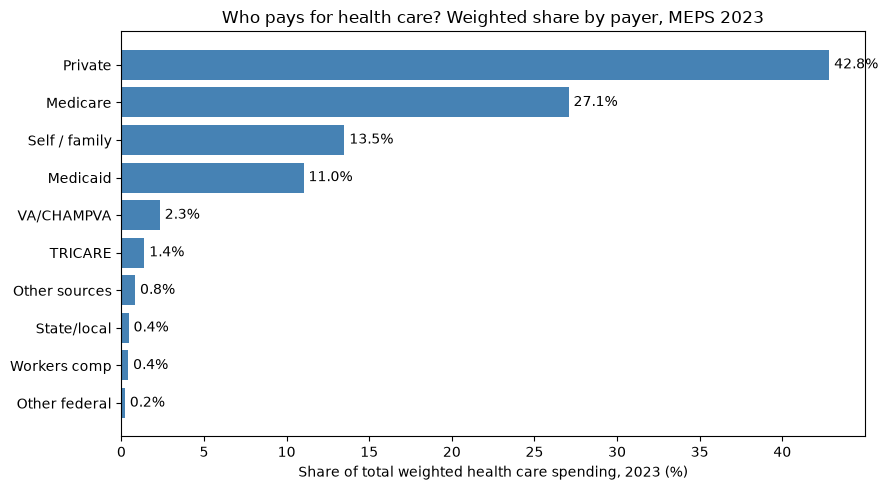

In [372]:
total_per_person = np.average(tot["TOTEXP23"], weights=w)
shares = pd.Series({name: np.average(tot[c], weights=w) / total_per_person
                    for c, name in payer_cols.items()}).sort_values()

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(shares.index, shares.values * 100, color="steelblue")
for i, v in enumerate(shares.values):
    ax.text(v * 100 + 0.3, i, f"{v*100:.1f}%", va="center")
ax.set_xlabel("Share of total weighted health care spending, 2023 (%)")
ax.set_title("Who pays for health care? Weighted share by payer, MEPS 2023")
fig.tight_layout()
plt.show()

### Who pays, by age group: mean spending per person

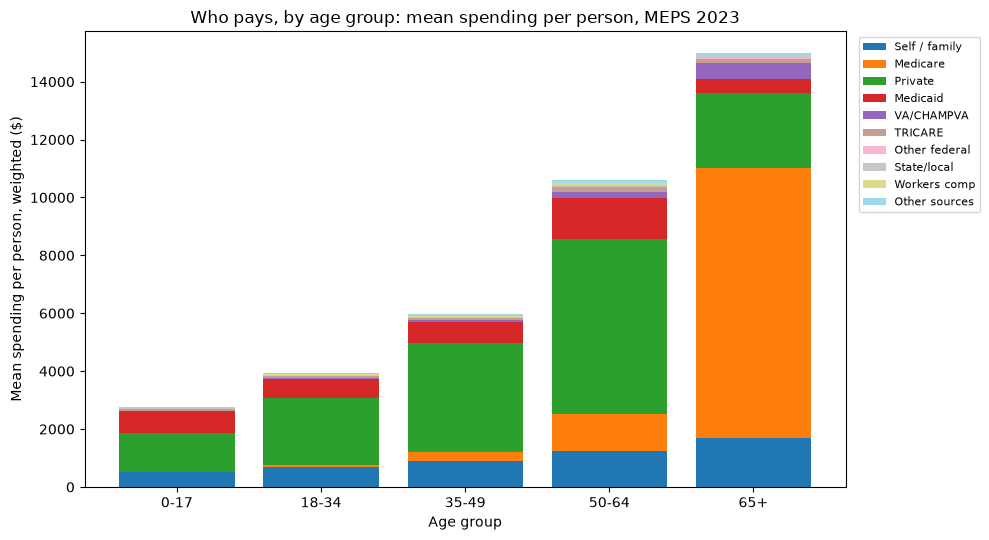

In [373]:
bins = [0, 17, 34, 49, 64, 130]
labels = ["0-17", "18-34", "35-49", "50-64", "65+"]
tot["agegrp"] = pd.cut(tot["AGE23X"], bins=bins, labels=labels)

by_age = {}
for c, name in payer_cols.items():
    by_age[name] = tot.groupby("agegrp", observed=True).apply(
        lambda x: np.average(x[c], weights=x["PERWT23F"]), include_groups=False
    ).round(0)
by_age = pd.DataFrame(by_age)

fig, ax = plt.subplots(figsize=(10, 5.5))
bottom = np.zeros(len(by_age))
colors = plt.cm.tab20(np.linspace(0, 1, len(by_age.columns)))
for col, color in zip(by_age.columns, colors):
    ax.bar(by_age.index.astype(str), by_age[col].values, bottom=bottom, label=col, color=color)
    bottom += by_age[col].values
ax.set_xlabel("Age group")
ax.set_ylabel("Mean spending per person, weighted ($)")
ax.set_title("Who pays, by age group: mean spending per person, MEPS 2023")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
fig.tight_layout()
plt.show()

### How each payer's spending is distributed

Log-scale histograms, among people for whom that payer paid something.

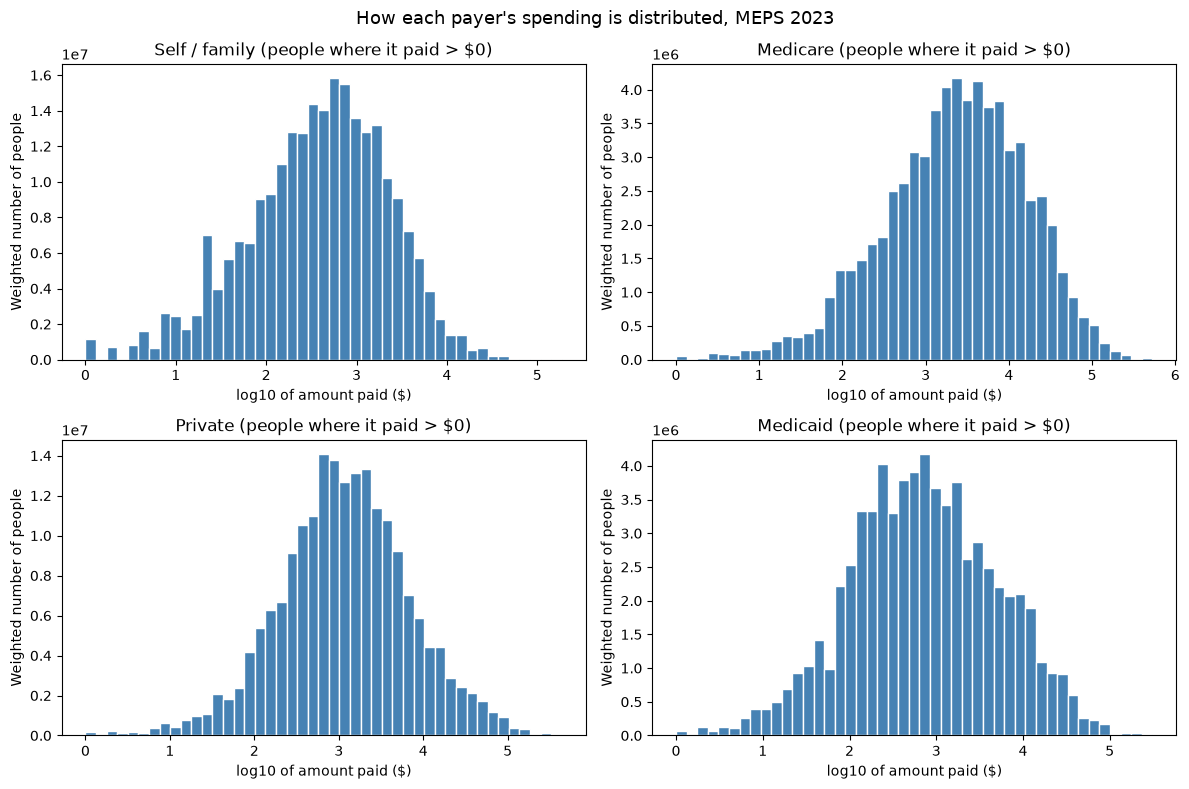

In [374]:
main_payers = {"TOTSLF23": "Self / family", "TOTMCR23": "Medicare",
               "TOTPRV23": "Private", "TOTMCD23": "Medicaid"}

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (c, name) in zip(axes.ravel(), main_payers.items()):
    paid = tot[tot[c] > 0]
    ax.hist(np.log10(paid[c]), bins=45, color="steelblue", edgecolor="white",
            weights=paid["PERWT23F"])
    ax.set_title(f"{name} (people where it paid > $0)")
    ax.set_xlabel("log10 of amount paid ($)")
    ax.set_ylabel("Weighted number of people")
fig.suptitle("How each payer's spending is distributed, MEPS 2023", fontsize=13)
fig.tight_layout()
plt.show()

### Concentration: how much spending the top spenders account for

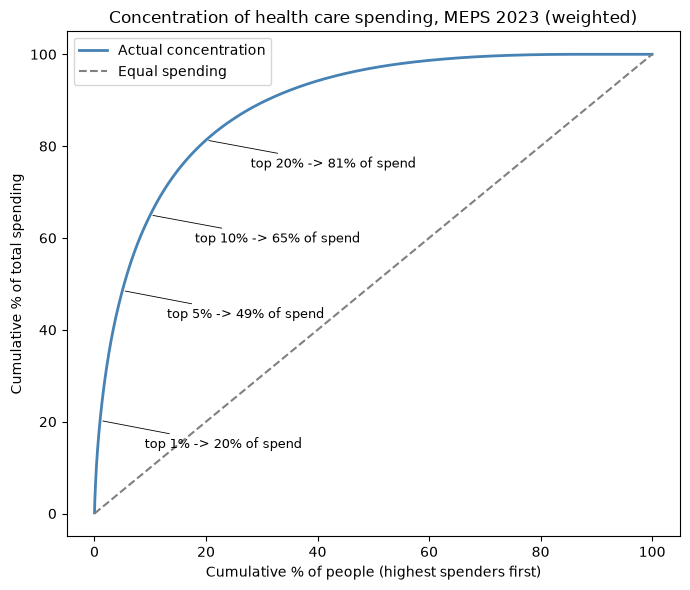

In [375]:
order = tot.sort_values("TOTEXP23", ascending=False)
cum_people = order["PERWT23F"].cumsum() / order["PERWT23F"].sum()
dollars = order["TOTEXP23"] * order["PERWT23F"]
cum_spend = dollars.cumsum() / dollars.sum()

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(cum_people * 100, cum_spend * 100, color="steelblue", lw=2, label="Actual concentration")
ax.plot([0, 100], [0, 100], ls="--", color="grey", label="Equal spending")
for p in [1, 5, 10, 20]:
    share_of_spend = np.interp(p / 100, cum_people.values, cum_spend.values)
    ax.annotate(f"top {p}% -> {share_of_spend*100:.0f}% of spend",
                xy=(p, share_of_spend * 100), xytext=(p + 8, share_of_spend * 100 - 6),
                arrowprops=dict(arrowstyle="-", lw=0.6), fontsize=9)
ax.set_xlabel("Cumulative % of people (highest spenders first)")
ax.set_ylabel("Cumulative % of total spending")
ax.set_title("Concentration of health care spending, MEPS 2023 (weighted)")
ax.legend()
fig.tight_layout()
plt.show()

### Out-of-pocket vs total spending

Points on the diagonal are people who paid their whole bill themselves. Out-of-pocket can't exceed total, so nothing sits above it.

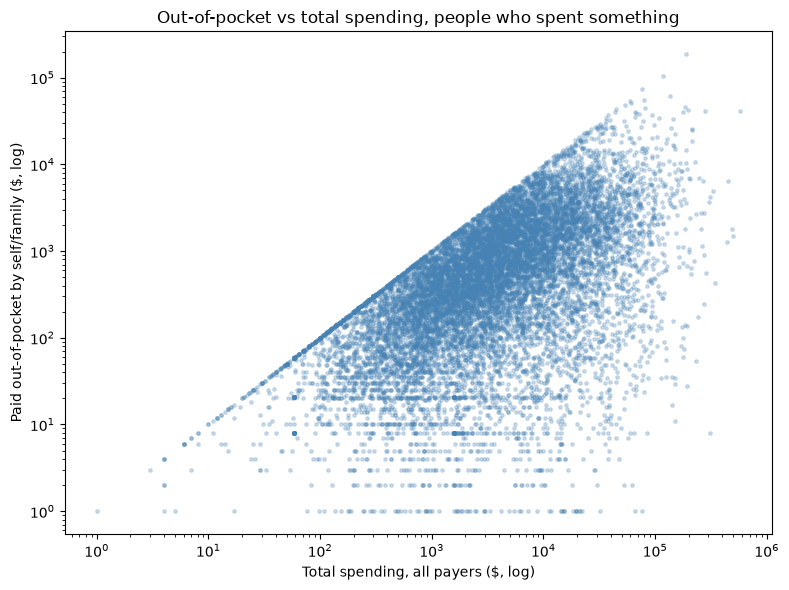

In [376]:
spenders = tot[tot["TOTEXP23"] > 0]
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(spenders["TOTEXP23"], spenders["TOTSLF23"].where(spenders["TOTSLF23"] > 0),
           s=6, alpha=0.25, color="steelblue")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Total spending, all payers ($, log)")
ax.set_ylabel("Paid out-of-pocket by self/family ($, log)")
ax.set_title("Out-of-pocket vs total spending, people who spent something")
fig.tight_layout()
plt.show()

## Age, sex, and region

Weighted by `PERWT23F`. People with no recorded age (148) and no region are dropped.

In [377]:
demo = pd.read_stata("../data/raw/meps/2023/h251.dta",
                     columns=["DUPERSID", "TOTEXP23", "AGE23X", "SEX", "REGION23", "PERWT23F"],
                     convert_categoricals=True)
demo = demo[(demo["AGE23X"] >= 0) & (demo["REGION23"].astype(str).str[0] != "-")].copy()
demo["SEX"] = demo["SEX"].astype(str).str[2:].str.title()
demo["REGION"] = demo["REGION23"].astype(str).str[2:].str.title()
demo["agegrp"] = pd.cut(demo["AGE23X"], [0, 17, 34, 49, 64, 130], labels=["0-17", "18-34", "35-49", "50-64", "65+"])

def wmean(x):
    return np.average(x["TOTEXP23"], weights=x["PERWT23F"])

def wmedian(x):
    s = x.sort_values("TOTEXP23")
    cum = s["PERWT23F"].cumsum() / s["PERWT23F"].sum()
    return s["TOTEXP23"].iloc[np.searchsorted(cum.values, 0.5)]

def wzero(x):
    return np.average(x["TOTEXP23"] == 0, weights=x["PERWT23F"])

def summary(group_col):
    rows = {k: {"people (M)": g["PERWT23F"].sum() / 1e6, "mean": wmean(g),
                "median": wmedian(g), "zero share": wzero(g)}
            for k, g in demo.groupby(group_col, observed=True)}
    return pd.DataFrame(rows).T

### Age: spending across the full age range

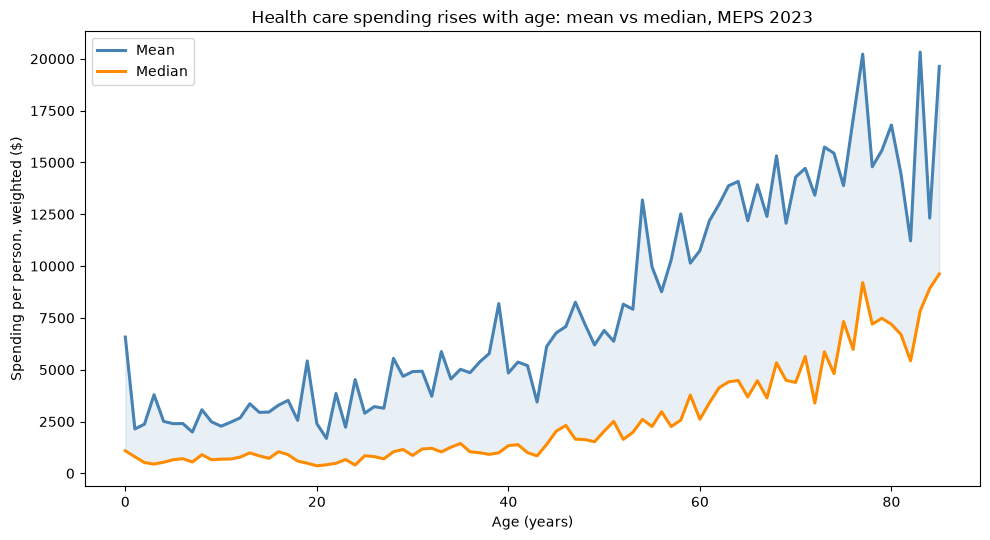

In [378]:
by_age = demo.groupby("AGE23X").apply(
    lambda g: pd.Series({"mean": wmean(g), "median": wmedian(g)}), include_groups=False)

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(by_age.index, by_age["mean"], color="steelblue", lw=2.2, label="Mean")
ax.plot(by_age.index, by_age["median"], color="darkorange", lw=2.2, label="Median")
ax.fill_between(by_age.index, by_age["median"], by_age["mean"], color="steelblue", alpha=0.12)
ax.set_xlabel("Age (years)")
ax.set_ylabel("Spending per person, weighted ($)")
ax.set_title("Health care spending rises with age: mean vs median, MEPS 2023")
ax.legend()
fig.tight_layout()
plt.show()

### Sex: women spend more on average, mostly between ages 18 and 64

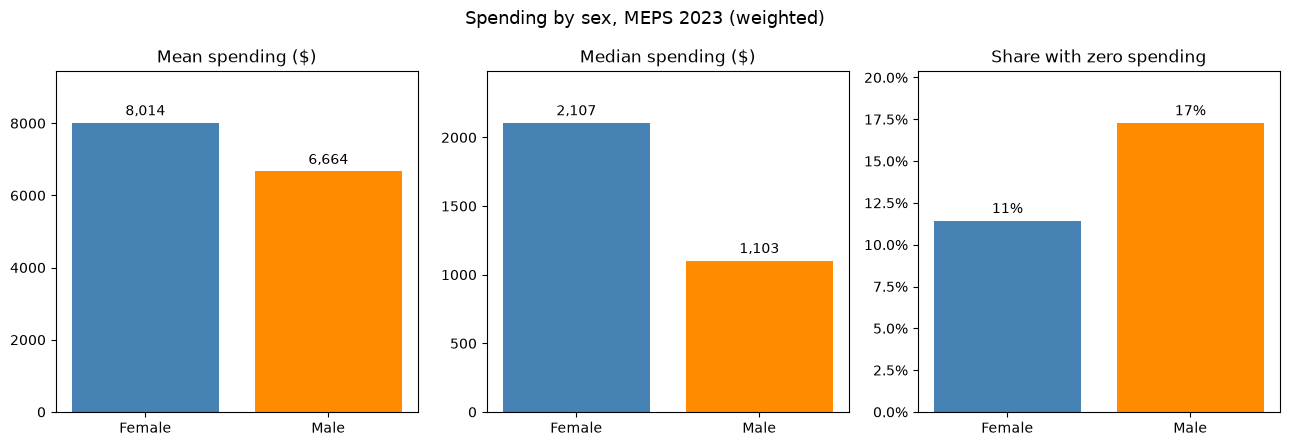

In [379]:
from matplotlib.ticker import PercentFormatter
s = summary("SEX")
fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
for ax, col, title, fmt in zip(axes, ["mean", "median", "zero share"],
                               ["Mean spending ($)", "Median spending ($)", "Share with zero spending"],
                               ["{:,.0f}", "{:,.0f}", "{:.0%}"]):
    bars = ax.bar(s.index, s[col], color=["steelblue", "darkorange"])
    ax.bar_label(bars, labels=[fmt.format(v) for v in s[col]], padding=3)
    ax.set_title(title)
    ax.set_ylim(0, s[col].max() * 1.18)
    if col == "zero share":
        ax.yaxis.set_major_formatter(PercentFormatter(1))
fig.suptitle("Spending by sex, MEPS 2023 (weighted)", fontsize=13)
fig.tight_layout()
plt.show()

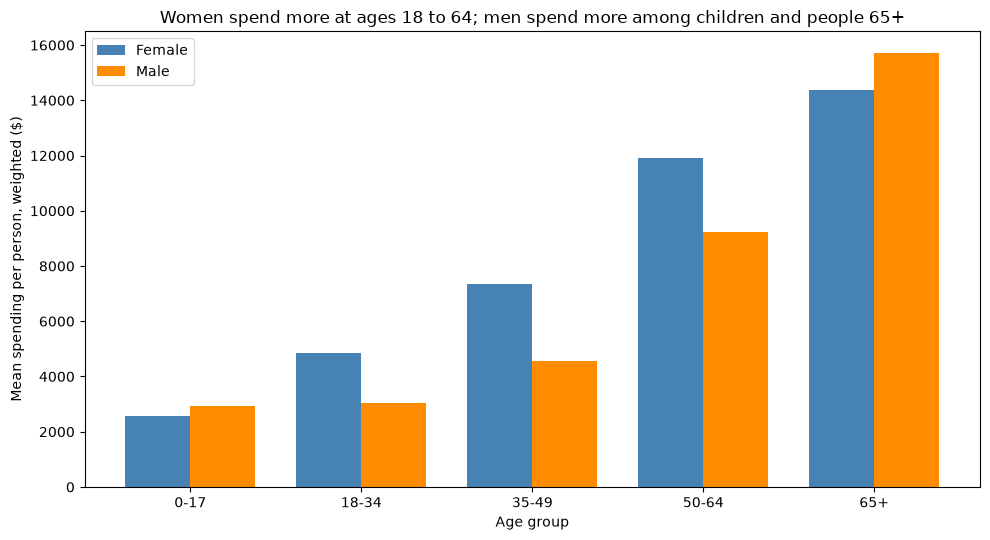

In [380]:
age_sex = demo.groupby(["agegrp", "SEX"], observed=True).apply(wmean, include_groups=False).unstack()

x = np.arange(len(age_sex.index))
width = 0.38
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.bar(x - width/2, age_sex["Female"], width, label="Female", color="steelblue")
ax.bar(x + width/2, age_sex["Male"], width, label="Male", color="darkorange")
ax.set_xticks(x)
ax.set_xticklabels(age_sex.index.astype(str))
ax.set_xlabel("Age group")
ax.set_ylabel("Mean spending per person, weighted ($)")
ax.set_title("Women spend more at ages 18 to 64; men spend more among children and people 65+")
ax.legend()
fig.tight_layout()
plt.show()

### Region: where people live

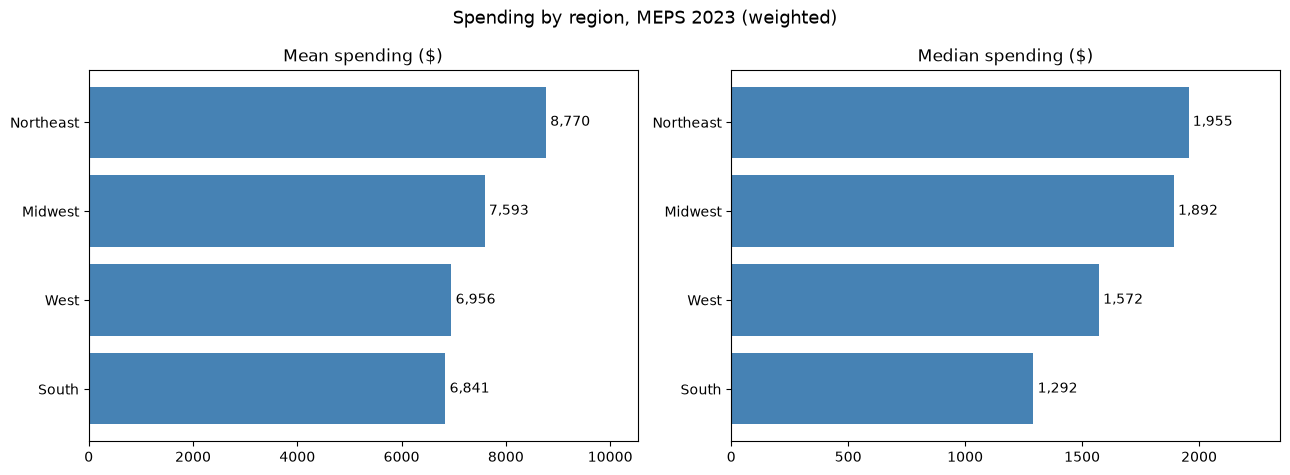

In [381]:
s = summary("REGION").sort_values("mean")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, col, title in zip(axes, ["mean", "median"], ["Mean spending ($)", "Median spending ($)"]):
    bars = ax.barh(s.index, s[col], color="steelblue")
    ax.bar_label(bars, labels=[f"{v:,.0f}" for v in s[col]], padding=3)
    ax.set_title(title)
    ax.set_xlim(0, s[col].max() * 1.2)
fig.suptitle("Spending by region, MEPS 2023 (weighted)", fontsize=13)
fig.tight_layout()
plt.show()

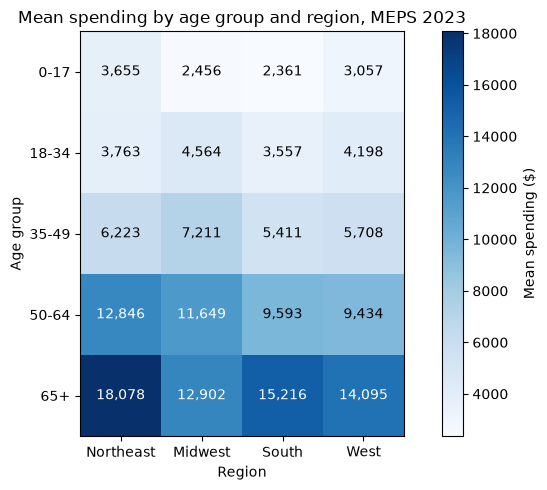

In [382]:
grid = demo.groupby(["agegrp", "REGION"], observed=True).apply(wmean, include_groups=False).unstack()
grid = grid[["Northeast", "Midwest", "South", "West"]]

fig, ax = plt.subplots(figsize=(8, 5))
im = ax.imshow(grid.values, cmap="Blues")
ax.set_xticks(range(grid.shape[1])); ax.set_xticklabels(grid.columns)
ax.set_yticks(range(grid.shape[0])); ax.set_yticklabels(grid.index.astype(str))
for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        v = grid.values[i, j]
        ax.text(j, i, f"{v:,.0f}", ha="center", va="center",
                color="white" if v > grid.values.max() * 0.6 else "black")
fig.colorbar(im, ax=ax, label="Mean spending ($)")
ax.set_xlabel("Region")
ax.set_ylabel("Age group")
ax.set_title("Mean spending by age group and region, MEPS 2023")
fig.tight_layout()
plt.show()

## Education: HIDEG and EDUCYR

These are only asked of adults, so this section keeps people aged 18 and over.

- **`HIDEG`** is the highest degree completed. Code 8 (under 16) is inapplicable, and -7 and -8 are refused or don't know. Those people are dropped.
- **`EDUCYR`** is years of education recorded when the person first entered MEPS. It isn't updated later, so it may not reflect their current education.

In [383]:
educ = pd.read_stata(
    "../data/raw/meps/2023/h251.dta",
    columns=["DUPERSID", "TOTEXP23", "AGE23X", "HIDEG", "EDUCYR", "PERWT23F"],
    convert_categoricals=True,
)
raw_educ = pd.read_stata("../data/raw/meps/2023/h251.dta", columns=["EDUCYR"], convert_categoricals=False)
educ["EDUCYR"] = raw_educ["EDUCYR"]

adults = educ[educ["AGE23X"] >= 18].copy()
adults = adults[~adults["HIDEG"].astype(str).str.startswith(("-8", "-7", "8 "))].copy()
adults["HIDEG"] = adults["HIDEG"].astype(str).str[2:].str.title()
adults["agegrp"] = pd.cut(adults["AGE23X"], [17, 34, 49, 64, 130], labels=["18-34", "35-49", "50-64", "65+"])

adults_yrs = adults[adults["EDUCYR"] >= 0].copy()
adults_yrs["years_band"] = pd.cut(
    adults_yrs["EDUCYR"], [-1, 11, 12, 15, 17],
    labels=["Under 12 years", "12 years", "13 to 15", "16 or more"],
)
print("adults with a valid degree:", len(adults), "| with valid EDUCYR:", len(adults_yrs))

adults with a valid degree: 14975 | with valid EDUCYR: 14924


### Highest degree: spending by degree

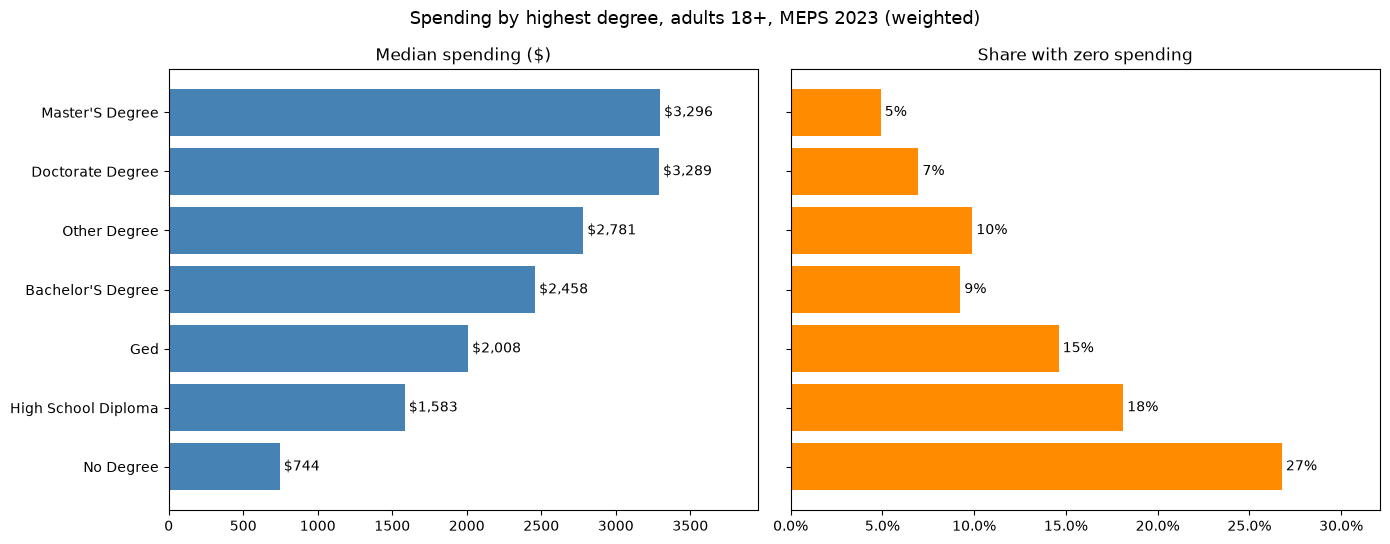

In [384]:
def summarize(df, col):
    rows = {}
    for k, g in df.groupby(col, observed=True):
        cum = g.sort_values("TOTEXP23")
        share = cum["PERWT23F"].cumsum() / cum["PERWT23F"].sum()
        rows[k] = {
            "people_M": g["PERWT23F"].sum() / 1e6,
            "mean": np.average(g["TOTEXP23"], weights=g["PERWT23F"]),
            "median": cum["TOTEXP23"].iloc[np.searchsorted(share.values, 0.5)],
            "zero_share": np.average(g["TOTEXP23"] == 0, weights=g["PERWT23F"]),
        }
    return pd.DataFrame(rows).T

by_degree = summarize(adults, "HIDEG").sort_values("median")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)
bars = axes[0].barh(by_degree.index, by_degree["median"], color="steelblue")
axes[0].bar_label(bars, labels=[f"${v:,.0f}" for v in by_degree["median"]], padding=3)
axes[0].set_title("Median spending ($)")
axes[0].set_xlim(0, by_degree["median"].max() * 1.2)

bars = axes[1].barh(by_degree.index, by_degree["zero_share"], color="darkorange")
axes[1].bar_label(bars, labels=[f"{v:.0%}" for v in by_degree["zero_share"]], padding=3)
axes[1].set_title("Share with zero spending")
axes[1].xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
axes[1].set_xlim(0, by_degree["zero_share"].max() * 1.2)

fig.suptitle("Spending by highest degree, adults 18+, MEPS 2023 (weighted)", fontsize=13)
fig.tight_layout()
plt.show()

Median spending rises with degree, from about $744 with no degree to over $3,000 with a master's or doctorate. The zero-spending share falls at the same time. Part of this is age: people with no degree are younger on average, so the next step compares within age groups.

### Years of education: spending across education bands

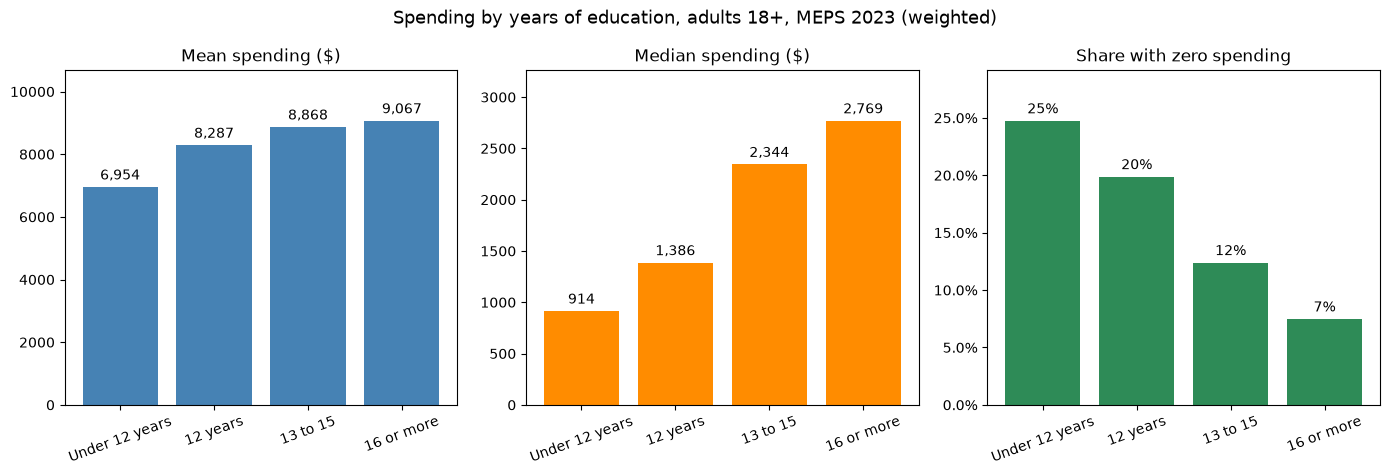

In [385]:
bands = summarize(adults_yrs, "years_band")
bands = bands.loc[["Under 12 years", "12 years", "13 to 15", "16 or more"]]

fig, axes = plt.subplots(1, 3, figsize=(14, 4.8))
for ax, col, title, color in zip(
    axes, ["mean", "median", "zero_share"],
    ["Mean spending ($)", "Median spending ($)", "Share with zero spending"],
    ["steelblue", "darkorange", "seagreen"],
):
    bars = ax.bar(bands.index.astype(str), bands[col], color=color)
    fmt = (lambda v: f"{v:.0%}") if col == "zero_share" else (lambda v: f"{v:,.0f}")
    ax.bar_label(bars, labels=[fmt(v) for v in bands[col]], padding=3)
    ax.set_title(title)
    ax.set_ylim(0, bands[col].max() * 1.18)
    ax.tick_params(axis="x", labelrotation=20)
    if col == "zero_share":
        ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
fig.suptitle("Spending by years of education, adults 18+, MEPS 2023 (weighted)", fontsize=13)
fig.tight_layout()
plt.show()

### Within age groups: does education still matter?

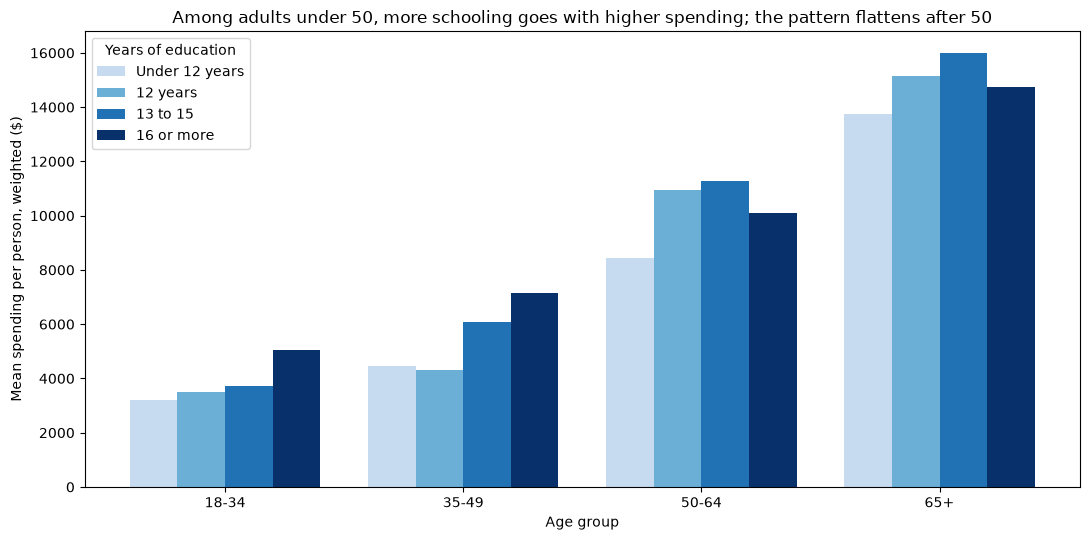

In [386]:
within = adults_yrs.groupby(["agegrp", "years_band"], observed=True).apply(
    lambda g: np.average(g["TOTEXP23"], weights=g["PERWT23F"]), include_groups=False
).unstack()

x = np.arange(len(within.index))
width = 0.2
colors = ["#c6dbef", "#6baed6", "#2171b5", "#08306b"]
fig, ax = plt.subplots(figsize=(11, 5.5))
for i, (col, color) in enumerate(zip(within.columns, colors)):
    ax.bar(x + (i - 1.5) * width, within[col], width, label=str(col), color=color)
ax.set_xticks(x)
ax.set_xticklabels(within.index.astype(str))
ax.set_xlabel("Age group")
ax.set_ylabel("Mean spending per person, weighted ($)")
ax.set_title("Among adults under 50, more schooling goes with higher spending; the pattern flattens after 50")
ax.legend(title="Years of education")
fig.tight_layout()
plt.show()

Adults under 50 with more schooling spend more on average, with the gap widening sharply from the under-12 group to the 16-plus group. From age 50 the pattern weakens, and at 65 and older the difference almost disappears. These are unadjusted comparisons, so income, insurance, and health status could explain part of the pattern.

## Income and marital status: POVCAT23, POVLEV23, FAMINC23, MARRY23X

- **`POVCAT23`** puts family income into five bands, from poor to high.
- **`POVLEV23`** is family income as a percent of the poverty line, continuous.
- **`FAMINC23`** is family income in dollars. Its rank order is almost the same as `POVLEV23`, so the comparison below checks whether it adds anything.
- **`MARRY23X`** is marital status, asked of adults only. Code 6 (under 16) is inapplicable. Codes -7 and -8 are dropped.

In [387]:
hh = pd.read_stata(
    "../data/raw/meps/2023/h251.dta",
    columns=["TOTEXP23", "AGE23X", "POVCAT23", "MARRY23X", "PERWT23F"],
    convert_categoricals=True,
)
raw_hh = pd.read_stata(
    "../data/raw/meps/2023/h251.dta",
    columns=["POVLEV23", "FAMINC23", "MARRY23X"],
    convert_categoricals=False,
)
hh["POVLEV23"] = raw_hh["POVLEV23"]
hh["FAMINC23"] = raw_hh["FAMINC23"]
hh["MARRY_CODE"] = raw_hh["MARRY23X"]

hh = hh[hh["AGE23X"] >= 0].copy()
hh["POVCAT23"] = hh["POVCAT23"].astype(str).str[2:].str.title()
hh["agegrp"] = pd.cut(hh["AGE23X"], [-1, 17, 34, 49, 64, 130],
                      labels=["0-17", "18-34", "35-49", "50-64", "65+"])

def weighted_median(df, col):
    s = df.sort_values(col)
    cum = s["PERWT23F"].cumsum() / s["PERWT23F"].sum()
    return s[col].iloc[np.searchsorted(cum.values, 0.5)]

def income_summary(df, col):
    rows = {}
    for k, g in df.groupby(col, observed=True):
        s = g.sort_values("TOTEXP23")
        cum = s["PERWT23F"].cumsum() / s["PERWT23F"].sum()
        rows[k] = {
            "people_M": g["PERWT23F"].sum() / 1e6,
            "mean": np.average(g["TOTEXP23"], weights=g["PERWT23F"]),
            "median": weighted_median(g, "TOTEXP23"),
            "zero_share": np.average(g["TOTEXP23"] == 0, weights=g["PERWT23F"]),
        }
    return pd.DataFrame(rows).T

### Income bands (POVCAT23): spending by family income category

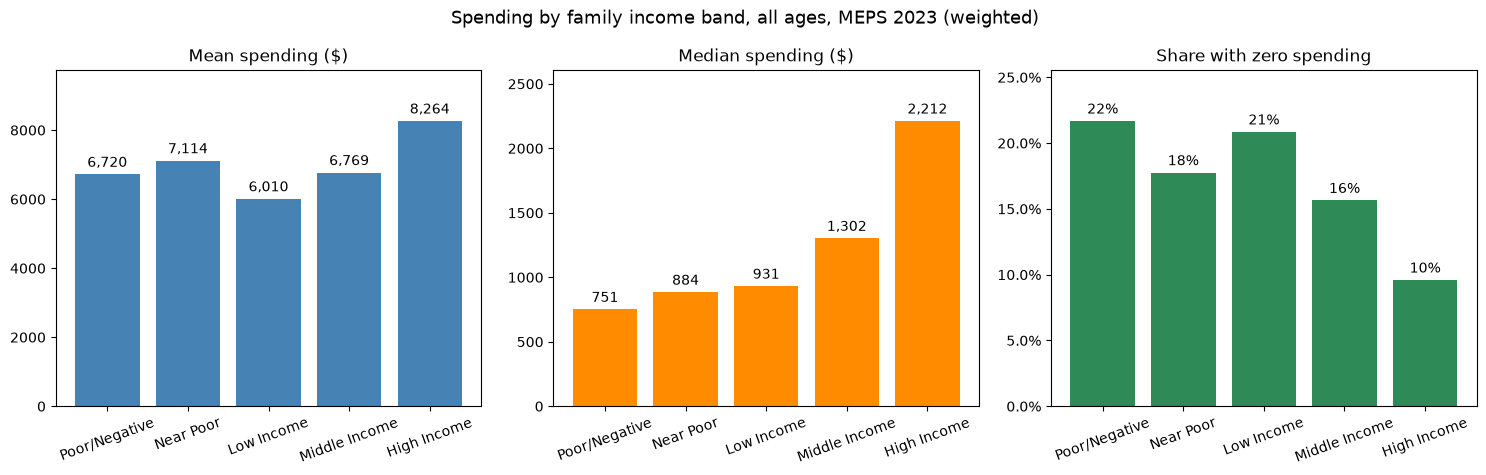

In [388]:
order = ["Poor/Negative", "Near Poor", "Low Income", "Middle Income", "High Income"]
bands = income_summary(hh, "POVCAT23").loc[order]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
for ax, col, title, color in zip(
    axes, ["mean", "median", "zero_share"],
    ["Mean spending ($)", "Median spending ($)", "Share with zero spending"],
    ["steelblue", "darkorange", "seagreen"],
):
    bars = ax.bar(bands.index, bands[col], color=color)
    fmt = (lambda v: f"{v:.0%}") if col == "zero_share" else (lambda v: f"{v:,.0f}")
    ax.bar_label(bars, labels=[fmt(v) for v in bands[col]], padding=3)
    ax.set_title(title)
    ax.set_ylim(0, bands[col].max() * 1.18)
    ax.tick_params(axis="x", labelrotation=20)
    if col == "zero_share":
        ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
fig.suptitle("Spending by family income band, all ages, MEPS 2023 (weighted)", fontsize=13)
fig.tight_layout()
plt.show()

The clearest signal is in the zero-spending share, which falls from about 22% in the poor band to about 10% in the high band. The median rises from about $750 to about $2,200. The mean is less orderly: the low band's mean is below the near-poor band's, because a few very high spenders in the upper bands pull the averages around.

### Continuous poverty ratio (POVLEV23): spending across deciles

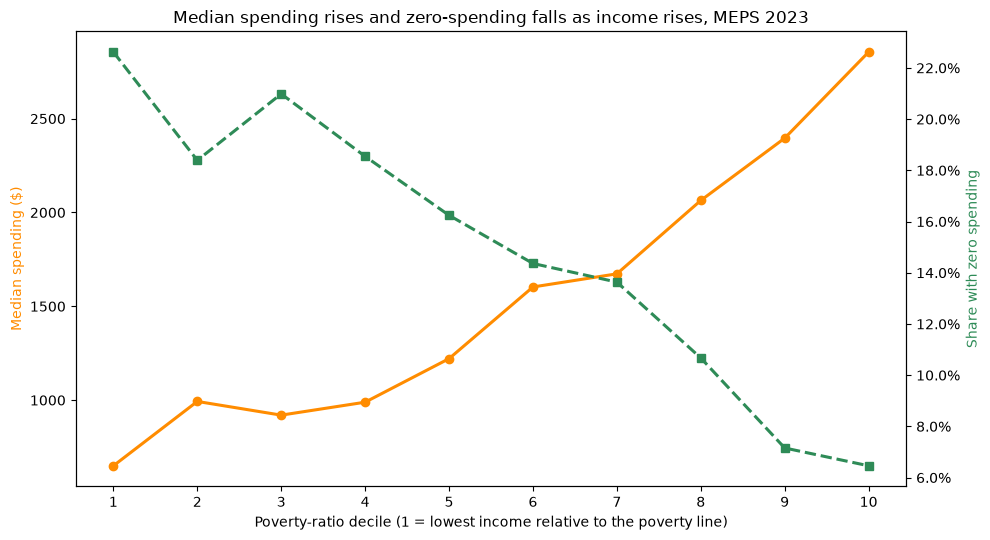

In [389]:
hh["pov_decile"] = pd.qcut(hh["POVLEV23"], 10, duplicates="drop")
deciles = pd.DataFrame({
    "median": hh.groupby("pov_decile", observed=True).apply(
        lambda g: weighted_median(g, "TOTEXP23"), include_groups=False),
    "zero_share": hh.groupby("pov_decile", observed=True).apply(
        lambda g: np.average(g["TOTEXP23"] == 0, weights=g["PERWT23F"]), include_groups=False),
}).reset_index(drop=True)
deciles.index = range(1, len(deciles) + 1)

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(deciles.index, deciles["median"], marker="o", color="darkorange", lw=2.2, label="Median spending ($)")
ax.set_xlabel("Poverty-ratio decile (1 = lowest income relative to the poverty line)")
ax.set_ylabel("Median spending ($)", color="darkorange")
ax.set_xticks(deciles.index)

ax2 = ax.twinx()
ax2.plot(deciles.index, deciles["zero_share"], marker="s", color="seagreen", lw=2.2, ls="--", label="Zero-spending share")
ax2.set_ylabel("Share with zero spending", color="seagreen")
ax2.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))

ax.set_title("Median spending rises and zero-spending falls as income rises, MEPS 2023")
fig.tight_layout()
plt.show()

Splitting the poverty ratio into deciles shows the same pattern more smoothly. The median rises from about $650 at the bottom to about $2,850 at the top, and the zero-spending share falls from about 23% to about 7%.

### Is income the same as the poverty ratio? And does income rank spending among spenders?

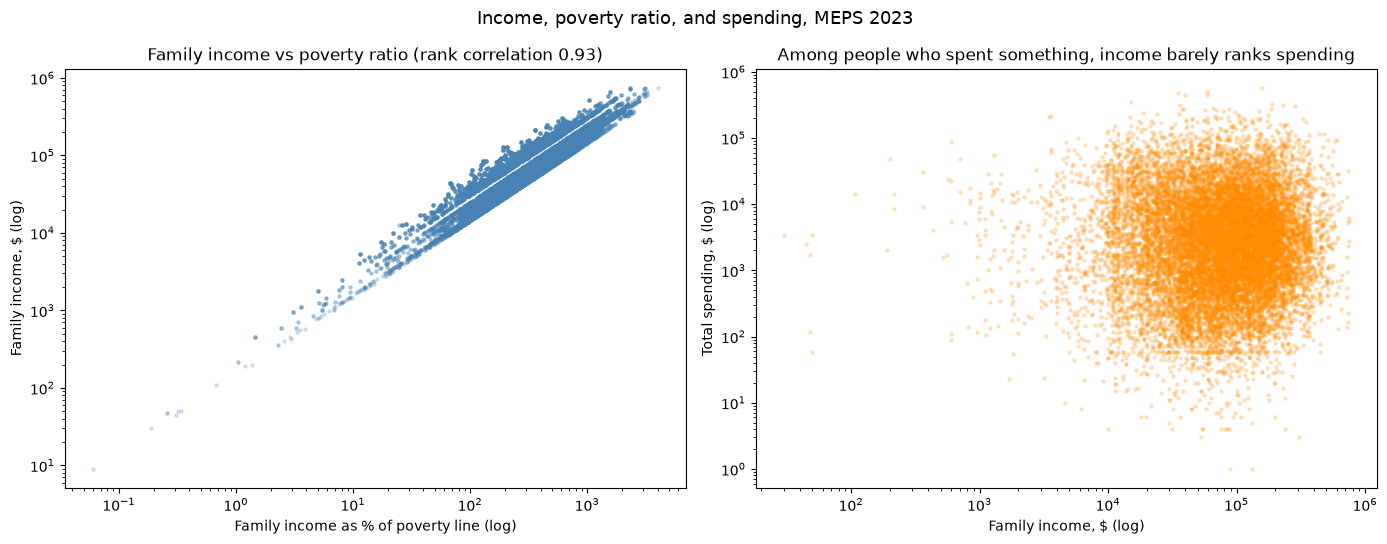

In [390]:
both = hh[hh["FAMINC23"] >= 0]
spenders = hh[(hh["TOTEXP23"] > 0) & (hh["FAMINC23"] >= 0)]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

axes[0].scatter(both["POVLEV23"], both["FAMINC23"], s=5, alpha=0.2, color="steelblue")
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_xlabel("Family income as % of poverty line (log)")
axes[0].set_ylabel("Family income, $ (log)")
axes[0].set_title("Family income vs poverty ratio (rank correlation 0.93)")

axes[1].scatter(spenders["FAMINC23"], spenders["TOTEXP23"], s=5, alpha=0.2, color="darkorange")
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_xlabel("Family income, $ (log)")
axes[1].set_ylabel("Total spending, $ (log)")
axes[1].set_title("Among people who spent something, income barely ranks spending")

fig.suptitle("Income, poverty ratio, and spending, MEPS 2023", fontsize=13)
fig.tight_layout()
plt.show()

The left panel shows that `FAMINC23` and `POVLEV23` track each other closely, so keeping both would add little. The right panel is the surprising one: among people who spent something, income has almost no rank correlation with how much they spent. Income is mainly linked to *whether* someone spends at all, not to the amount among spenders.

### Marital status (MARRY23X): adults only

Groups are married, never married, and previously married (divorced, separated, or widowed). Previously married is combined because the three groups are small.

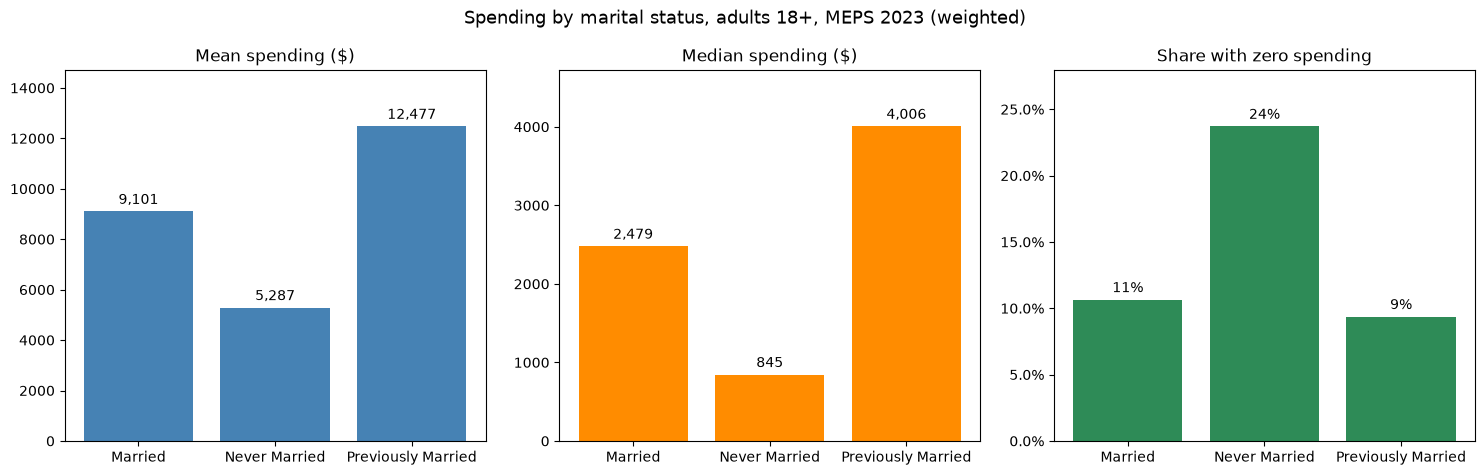

In [391]:
adults_m = hh[(hh["AGE23X"] >= 18) & (hh["MARRY_CODE"] > 0)].copy()
adults_m["marital"] = adults_m["MARRY23X"].astype(str).str[2:].str.title().replace({
    "Divorced": "Previously Married", "Widowed": "Previously Married", "Separated": "Previously Married",
})
marital = income_summary(adults_m, "marital").loc[["Married", "Never Married", "Previously Married"]]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
for ax, col, title, color in zip(
    axes, ["mean", "median", "zero_share"],
    ["Mean spending ($)", "Median spending ($)", "Share with zero spending"],
    ["steelblue", "darkorange", "seagreen"],
):
    bars = ax.bar(marital.index, marital[col], color=color)
    fmt = (lambda v: f"{v:.0%}") if col == "zero_share" else (lambda v: f"{v:,.0f}")
    ax.bar_label(bars, labels=[fmt(v) for v in marital[col]], padding=3)
    ax.set_title(title)
    ax.set_ylim(0, marital[col].max() * 1.18)
    if col == "zero_share":
        ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
fig.suptitle("Spending by marital status, adults 18+, MEPS 2023 (weighted)", fontsize=13)
fig.tight_layout()
plt.show()

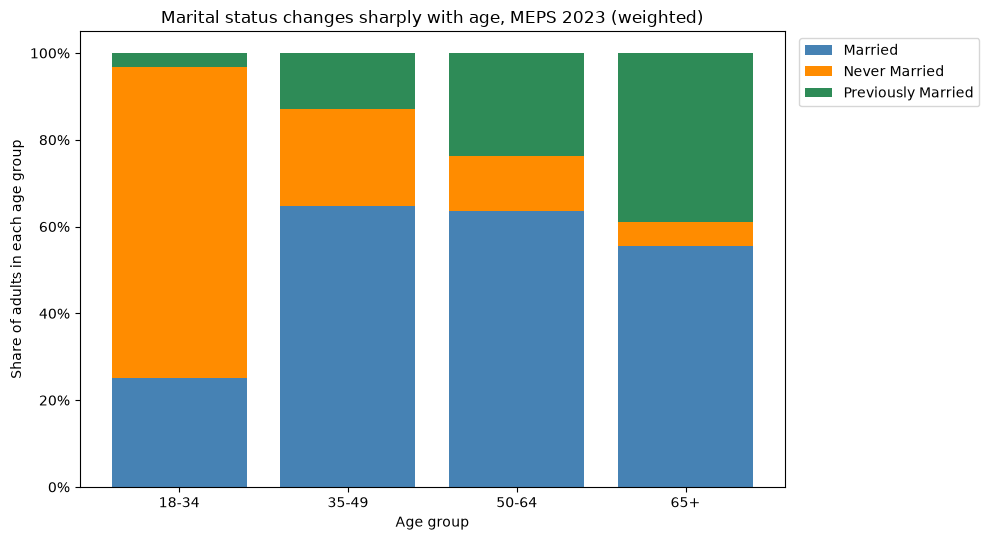

In [392]:
age_mix = adults_m.groupby(["agegrp", "marital"], observed=True).apply(
    lambda g: g["PERWT23F"].sum(), include_groups=False
).unstack()
age_mix = age_mix.div(age_mix.sum(axis=1), axis=0)[["Married", "Never Married", "Previously Married"]]

fig, ax = plt.subplots(figsize=(10, 5.5))
bottom = np.zeros(len(age_mix))
for col, color in zip(age_mix.columns, ["steelblue", "darkorange", "seagreen"]):
    ax.bar(age_mix.index.astype(str), age_mix[col], bottom=bottom, label=col, color=color)
    bottom += age_mix[col].values
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set_xlabel("Age group")
ax.set_ylabel("Share of adults in each age group")
ax.set_title("Marital status changes sharply with age, MEPS 2023 (weighted)")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
fig.tight_layout()
plt.show()

Marital status is strongly tied to age. Most adults under 35 have never married, and most adults from 35 to 64 are married. That means the raw marital differences above mix age with marital status. The next chart separates them.

### Within age groups: median spending by marital status

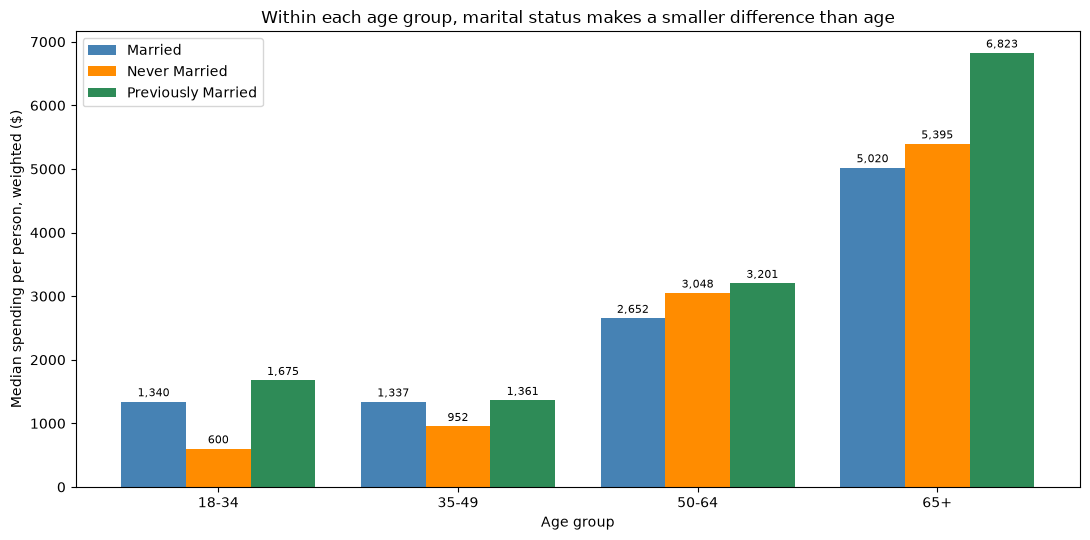

In [393]:
within_m = adults_m.groupby(["agegrp", "marital"], observed=True).apply(
    lambda g: weighted_median(g, "TOTEXP23"), include_groups=False
).unstack()[["Married", "Never Married", "Previously Married"]]

x = np.arange(len(within_m.index))
width = 0.27
fig, ax = plt.subplots(figsize=(11, 5.5))
for i, (col, color) in enumerate(zip(within_m.columns, ["steelblue", "darkorange", "seagreen"])):
    bars = ax.bar(x + (i - 1) * width, within_m[col], width, label=col, color=color)
    ax.bar_label(bars, labels=[f"{v:,.0f}" for v in within_m[col]], padding=2, fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels(within_m.index.astype(str))
ax.set_xlabel("Age group")
ax.set_ylabel("Median spending per person, weighted ($)")
ax.set_title("Within each age group, marital status makes a smaller difference than age")
ax.legend()
fig.tight_layout()
plt.show()

Medians are used here because the means are dominated by a few very large spenders. Within each age group, the differences between married, never-married, and previously married adults are much smaller than the differences across age groups. Without adjustment, the raw marital comparisons mostly reflect who is older.

## Diagnoses: chronic conditions

Each flag records whether the person reported the condition in the interview: 1 = yes, 2 = no. Codes -1 (inapplicable), -7 (refused), -8 (don't know), and -15 (cancer only) are dropped.

The eight conditions below were asked of adults only. Asthma and diabetes were also asked of children, so they're left out of this section, and you can add them later as a separate group.

Diagnoses rise with age, so every spending comparison here is shown both raw and within age groups.

In [394]:
dx_cols = ['HIBPDX', 'CHDDX', 'MIDX', 'STRKDX', 'EMPHDX', 'CHOLDX', 'CANCERDX', 'ARTHDX']
dx_names = {'HIBPDX': 'High blood pressure', 'CHDDX': 'Coronary heart disease', 'MIDX': 'Heart attack', 'STRKDX': 'Stroke', 'EMPHDX': 'Emphysema', 'CHOLDX': 'High cholesterol', 'CANCERDX': 'Cancer', 'ARTHDX': 'Arthritis'}

raw_dx = pd.read_stata(
    "../data/raw/meps/2023/h251.dta",
    columns=["TOTEXP23", "AGE23X", "PERWT23F"] + dx_cols,
    convert_categoricals=False,
)
adults_dx = raw_dx[raw_dx["AGE23X"] >= 18].copy()
adults_dx["agegrp"] = pd.cut(adults_dx["AGE23X"], [17, 34, 49, 64, 130],
                             labels=["18-34", "35-49", "50-64", "65+"])

def dx_median(df):
    s = df.sort_values("TOTEXP23")
    cum = s["PERWT23F"].cumsum() / s["PERWT23F"].sum()
    return s["TOTEXP23"].iloc[np.searchsorted(cum.values, 0.5)]

def dx_prevalence_table():
    rows = {}
    for c in dx_cols:
        valid = adults_dx[adults_dx[c].isin([1, 2])]
        rows[dx_names[c]] = np.average(valid[c] == 1, weights=valid["PERWT23F"])
    return pd.Series(rows)

print("adults 18+:", len(adults_dx))
print(dx_prevalence_table().sort_values(ascending=False).round(3).to_string())

adults 18+: 15123
High blood pressure       0.322
High cholesterol          0.309
Arthritis                 0.245
Cancer                    0.113
Coronary heart disease    0.047
Stroke                    0.038
Heart attack              0.031
Emphysema                 0.013


### How common is each condition among adults?

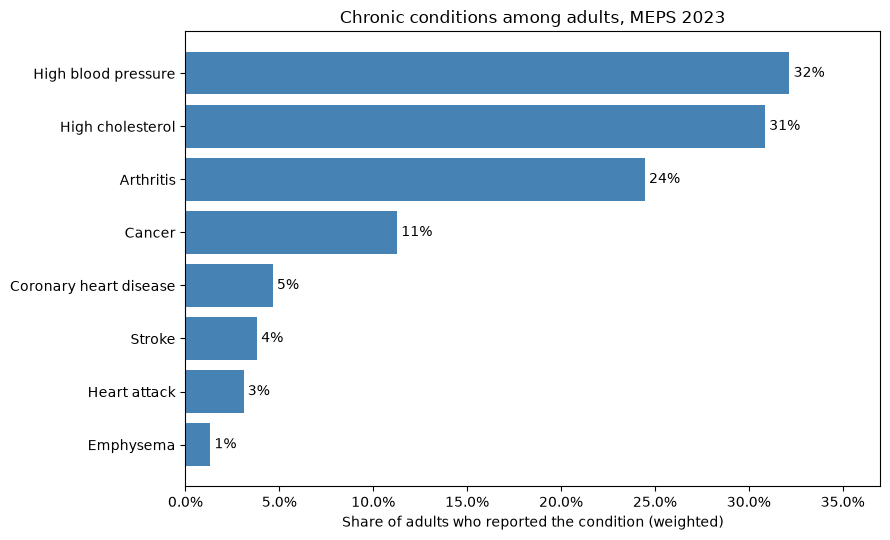

In [395]:
prev = dx_prevalence_table().sort_values()

fig, ax = plt.subplots(figsize=(9, 5.5))
bars = ax.barh(prev.index, prev.values, color="steelblue")
ax.bar_label(bars, labels=[f"{v:.0%}" for v in prev.values], padding=3)
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set_xlim(0, prev.max() * 1.15)
ax.set_xlabel("Share of adults who reported the condition (weighted)")
ax.set_title("Chronic conditions among adults, MEPS 2023")
fig.tight_layout()
plt.show()

High blood pressure, high cholesterol, and arthritis are the most common, each affecting roughly a quarter to a third of adults. Heart attack, stroke, and emphysema are rare, and those rare conditions tend to be the ones with the largest spending.

### Spending with and without each condition: raw and within age groups

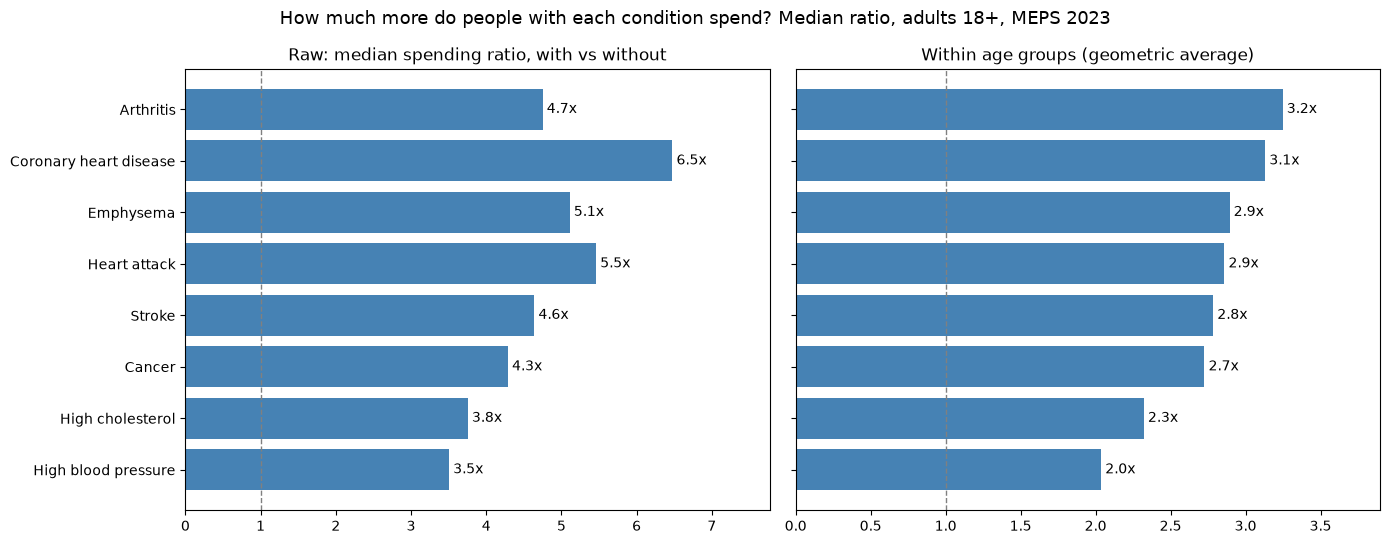

In [396]:
rows = []
for c in dx_cols:
    valid = adults_dx[adults_dx[c].isin([1, 2])]
    yes = valid[valid[c] == 1]
    no = valid[valid[c] == 2]
    within = []
    for _, g in valid.groupby("agegrp", observed=True):
        gy, gn = g[g[c] == 1], g[g[c] == 2]
        if len(gy) > 30 and len(gn) > 30:
            within.append(dx_median(gy) / dx_median(gn))
    rows.append({
        "condition": dx_names[c],
        "raw_ratio": dx_median(yes) / dx_median(no),
        "within_age_ratio": np.exp(np.mean(np.log(within))),
    })
ratios = pd.DataFrame(rows).set_index("condition").sort_values("within_age_ratio")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)
for ax, col, title in zip(axes, ["raw_ratio", "within_age_ratio"],
                          ["Raw: median spending ratio, with vs without", "Within age groups (geometric average)"]):
    bars = ax.barh(ratios.index, ratios[col], color="steelblue")
    ax.bar_label(bars, labels=[f"{v:.1f}x" for v in ratios[col]], padding=3)
    ax.axvline(1, color="grey", ls="--", lw=1)
    ax.set_title(title)
    ax.set_xlim(0, ratios[col].max() * 1.2)
fig.suptitle("How much more do people with each condition spend? Median ratio, adults 18+, MEPS 2023", fontsize=13)
fig.tight_layout()
plt.show()

Among adults, people with any of these conditions have a much higher median spending than those without. Part of this is age, since the raw ratios are larger than the within-age ones. Even after holding age fixed, the medians are about 2 to 3 times higher with most conditions.

These are associations, and the diagnosis and spending come from the same year. Some diagnoses are made during care that was itself costly, so these ratios overstate the effect of having the condition.

### Number of conditions

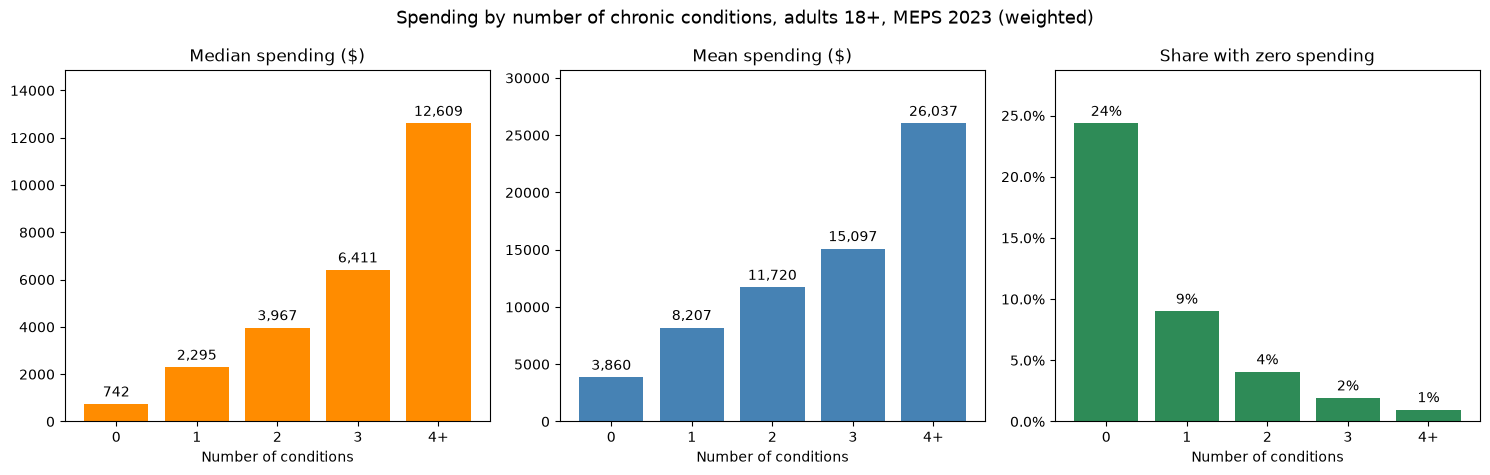

In [397]:
adults_dx["n_conditions"] = adults_dx[dx_cols].eq(1).sum(axis=1).clip(upper=4)
levels = adults_dx.groupby("n_conditions").apply(
    lambda g: pd.Series({
        "share_of_adults": g["PERWT23F"].sum() / adults_dx["PERWT23F"].sum(),
        "mean": np.average(g["TOTEXP23"], weights=g["PERWT23F"]),
        "median": dx_median(g),
        "zero_share": np.average(g["TOTEXP23"] == 0, weights=g["PERWT23F"]),
    }),
    include_groups=False,
)
levels.index = ["0", "1", "2", "3", "4+"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
for ax, col, title, color in zip(
    axes, ["median", "mean", "zero_share"],
    ["Median spending ($)", "Mean spending ($)", "Share with zero spending"],
    ["darkorange", "steelblue", "seagreen"],
):
    bars = ax.bar(levels.index, levels[col], color=color)
    fmt = (lambda v: f"{v:.0%}") if col == "zero_share" else (lambda v: f"{v:,.0f}")
    ax.bar_label(bars, labels=[fmt(v) for v in levels[col]], padding=3)
    ax.set_title(title)
    ax.set_xlabel("Number of conditions")
    ax.set_ylim(0, levels[col].max() * 1.18)
    if col == "zero_share":
        ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
fig.suptitle("Spending by number of chronic conditions, adults 18+, MEPS 2023 (weighted)", fontsize=13)
fig.tight_layout()
plt.show()

Spending climbs steadily with each additional condition. The median rises about seventeen-fold, from roughly $740 with no conditions to about $12,600 with four or more, and the zero-spending share drops. The share of adults with no conditions is close to half, so the group with four or more conditions is small but accounts for a large share of spending.

### Why age matters: prevalence by age group

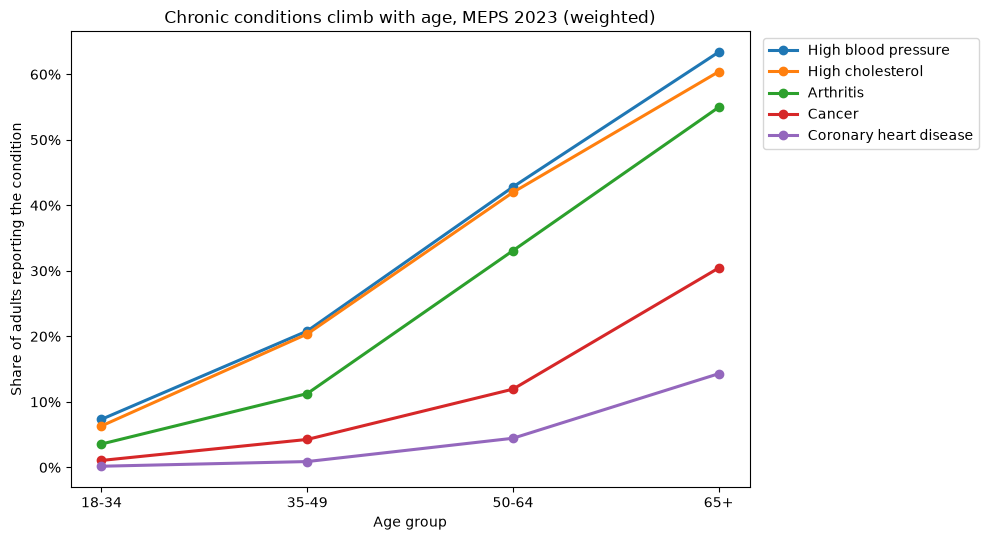

In [398]:
def prevalence(g, c):
    valid = g[g[c].isin([1, 2])]
    return np.average(valid[c] == 1, weights=valid["PERWT23F"])

prev_age = adults_dx.groupby("agegrp", observed=True).apply(
    lambda g: pd.Series({dx_names[c]: prevalence(g, c) for c in dx_cols}),
    include_groups=False,
)
pick = ["High blood pressure", "High cholesterol", "Arthritis", "Cancer", "Coronary heart disease"]

fig, ax = plt.subplots(figsize=(10, 5.5))
for name in pick:
    ax.plot(prev_age.index.astype(str), prev_age[name], marker="o", lw=2.2, label=name)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set_xlabel("Age group")
ax.set_ylabel("Share of adults reporting the condition")
ax.set_title("Chronic conditions climb with age, MEPS 2023 (weighted)")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
fig.tight_layout()
plt.show()

Most of these conditions become more common with age, which is why the raw comparisons overstate the link to spending. Blood pressure and cholesterol climb steeply from midlife on, and cancer rises about 2.5 times between ages 50-64 and 65+.

## Smoking: OFTSMK53

Asked of adults only. The answer is how often the person smoked cigarettes: 1 = every day, 2 = some days, 3 = not at all. Codes -1 (inapplicable), -7 (refused), and -8 (don't know) are dropped, along with the 27 children who have an answer.

"Current smoker" below combines every day and some days.

In [399]:
smk = pd.read_stata(
    "../data/raw/meps/2023/h251.dta",
    columns=["TOTEXP23", "AGE23X", "OFTSMK53", "PERWT23F"],
    convert_categoricals=False,
)
smk = smk[(smk["AGE23X"] >= 18) & (smk["OFTSMK53"].isin([1, 2, 3]))].copy()
smk["status"] = smk["OFTSMK53"].map({1: "Every day", 2: "Some days", 3: "Not at all"})
smk["smoker"] = np.where(smk["OFTSMK53"].isin([1, 2]), "Current smoker", "Non-smoker")
smk["agegrp"] = pd.cut(smk["AGE23X"], [17, 34, 49, 64, 130], labels=["18-34", "35-49", "50-64", "65+"])

def smk_summary(g):
    s = g.sort_values("TOTEXP23")
    cum = s["PERWT23F"].cumsum() / s["PERWT23F"].sum()
    return pd.Series({
        "people_M": g["PERWT23F"].sum() / 1e6,
        "mean": np.average(g["TOTEXP23"], weights=g["PERWT23F"]),
        "median": s["TOTEXP23"].iloc[np.searchsorted(cum.values, 0.5)],
        "zero_share": np.average(g["TOTEXP23"] == 0, weights=g["PERWT23F"]),
    })

print("adults with a valid answer:", len(smk))
print("current smokers (weighted share):", round(np.average(smk["smoker"] == "Current smoker", weights=smk["PERWT23F"]), 3))

adults with a valid answer: 14889
current smokers (weighted share): 0.109


### Spending by smoking frequency

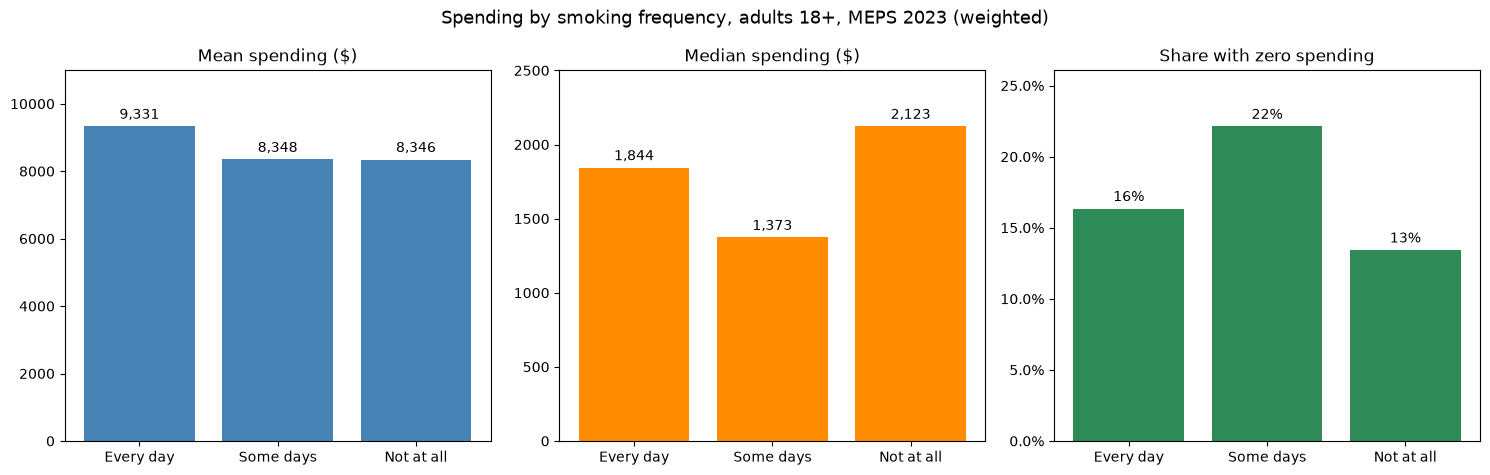

In [400]:
by_status = smk.groupby("status").apply(smk_summary, include_groups=False).loc[["Every day", "Some days", "Not at all"]]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
for ax, col, title, color in zip(
    axes, ["mean", "median", "zero_share"],
    ["Mean spending ($)", "Median spending ($)", "Share with zero spending"],
    ["steelblue", "darkorange", "seagreen"],
):
    bars = ax.bar(by_status.index, by_status[col], color=color)
    fmt = (lambda v: f"{v:.0%}") if col == "zero_share" else (lambda v: f"{v:,.0f}")
    ax.bar_label(bars, labels=[fmt(v) for v in by_status[col]], padding=3)
    ax.set_title(title)
    ax.set_ylim(0, by_status[col].max() * 1.18)
    if col == "zero_share":
        ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
fig.suptitle("Spending by smoking frequency, adults 18+, MEPS 2023 (weighted)", fontsize=13)
fig.tight_layout()
plt.show()

Means look similar across the three groups, but medians are lower for people who smoke, and the share with zero spending is higher. Median spending is about $1,700 for current smokers and $2,100 for non-smokers. Current smokers are also slightly older on average, which matters for the next comparison.

### Within age groups: current smokers vs non-smokers

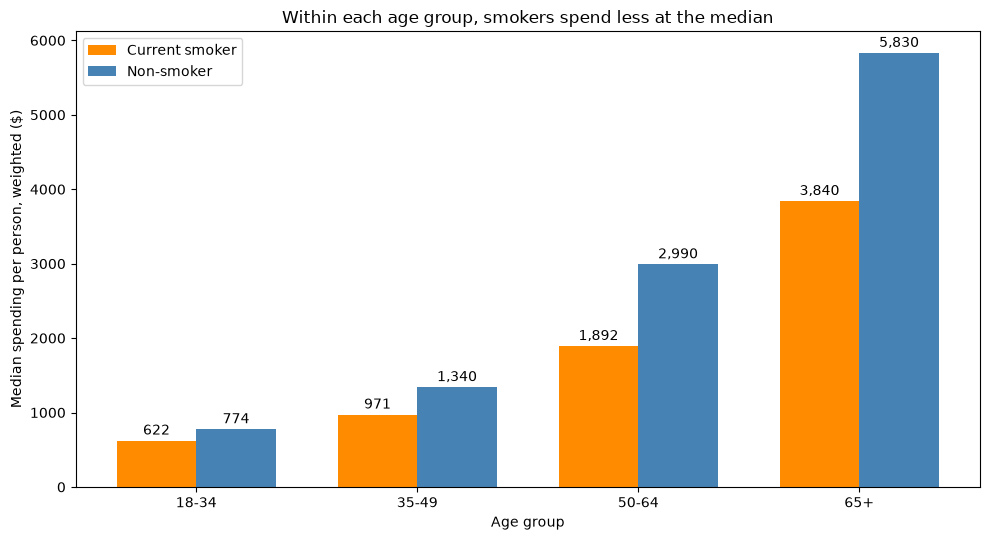

In [401]:
within = smk.groupby(["agegrp", "smoker"], observed=True).apply(
    lambda g: smk_summary(g)["median"], include_groups=False
).unstack()

x = np.arange(len(within.index))
width = 0.36
fig, ax = plt.subplots(figsize=(10, 5.5))
for i, (col, color) in enumerate(zip(within.columns, ["darkorange", "steelblue"])):
    bars = ax.bar(x + (i - 0.5) * width, within[col], width, label=col, color=color)
    ax.bar_label(bars, labels=[f"{v:,.0f}" for v in within[col]], padding=2)
ax.set_xticks(x)
ax.set_xticklabels(within.index.astype(str))
ax.set_xlabel("Age group")
ax.set_ylabel("Median spending per person, weighted ($)")
ax.set_title("Within each age group, smokers spend less at the median")
ax.legend()
fig.tight_layout()
plt.show()

The median gap holds within every age group, and in relative terms it is largest for people 50 to 64 (about 37% lower). Smoking is more common in the middle age groups, which is why the raw comparison above can mix age with smoking.

Smokers' lower medians sit alongside a higher zero-spending share. That makes sense if some smokers avoid care, though the data can't show why.

### Smoking prevalence by age

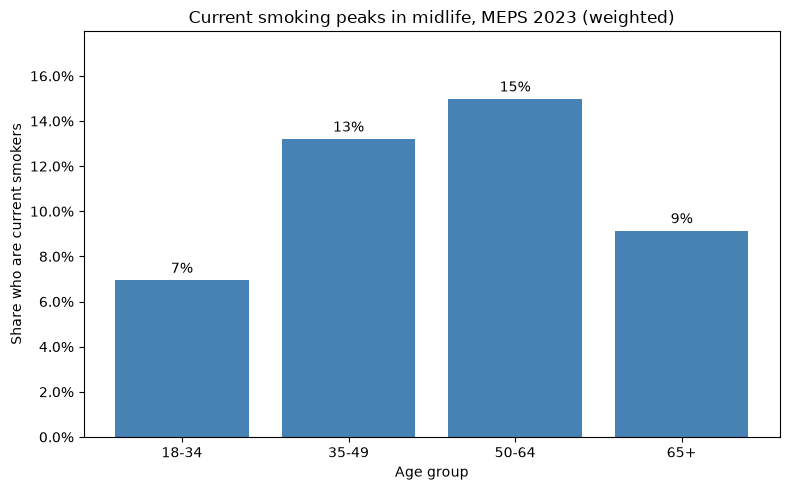

In [402]:
prev = smk.groupby("agegrp", observed=True).apply(
    lambda g: np.average(g["smoker"] == "Current smoker", weights=g["PERWT23F"]),
    include_groups=False,
)

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(prev.index.astype(str), prev.values, color="steelblue")
ax.bar_label(bars, labels=[f"{v:.0%}" for v in prev.values], padding=3)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set_ylim(0, prev.max() * 1.2)
ax.set_xlabel("Age group")
ax.set_ylabel("Share who are current smokers")
ax.set_title("Current smoking peaks in midlife, MEPS 2023 (weighted)")
fig.tight_layout()
plt.show()

Smoking is rare among younger adults and drops among people 65 and older, which may reflect people quitting or dying earlier. The data can't tell which. Among adults 18 and over, about 11% are current smokers.

Smoking is a cause of many of the conditions in the diagnosis section. If you adjust for those conditions, you estimate only the part of smoking's effect that doesn't run through them. Decide which question you're asking before you choose.

## Insurance coverage: INSCOV23

Coverage during 2023: 1 = any private insurance, 2 = public only, 3 = uninsured. There are no special codes. The 148 people with no age are dropped.

`INSCOV23` is a predictor, not an outcome, so it's safe to use. The payer columns from the first section, which describe how the bill was paid, still aren't.

In [403]:
ins = pd.read_stata(
    "../data/raw/meps/2023/h251.dta",
    columns=["TOTEXP23", "TOTSLF23", "AGE23X", "INSCOV23", "PERWT23F"],
    convert_categoricals=False,
)
ins = ins[ins["AGE23X"] >= 0].copy()
ins["coverage"] = ins["INSCOV23"].map({1: "Any private", 2: "Public only", 3: "Uninsured"})
ins["agegrp"] = pd.cut(ins["AGE23X"], [-1, 17, 34, 49, 64, 130],
                       labels=["0-17", "18-34", "35-49", "50-64", "65+"])

def ins_summary(g):
    s = g.sort_values("TOTEXP23")
    cum = s["PERWT23F"].cumsum() / s["PERWT23F"].sum()
    return pd.Series({
        "people_M": g["PERWT23F"].sum() / 1e6,
        "mean": np.average(g["TOTEXP23"], weights=g["PERWT23F"]),
        "median": s["TOTEXP23"].iloc[np.searchsorted(cum.values, 0.5)],
        "zero_share": np.average(g["TOTEXP23"] == 0, weights=g["PERWT23F"]),
        "self_pay_share": np.average(g["TOTSLF23"], weights=g["PERWT23F"]) / np.average(g["TOTEXP23"], weights=g["PERWT23F"]),
    })

print("people with a coverage answer:", len(ins))
print(ins.groupby("coverage")["PERWT23F"].sum().div(1e6).round(1).to_dict())

people with a coverage answer: 18771
{'Any private': 215.2, 'Public only': 95.9, 'Uninsured': 20.9}


### Spending by coverage type

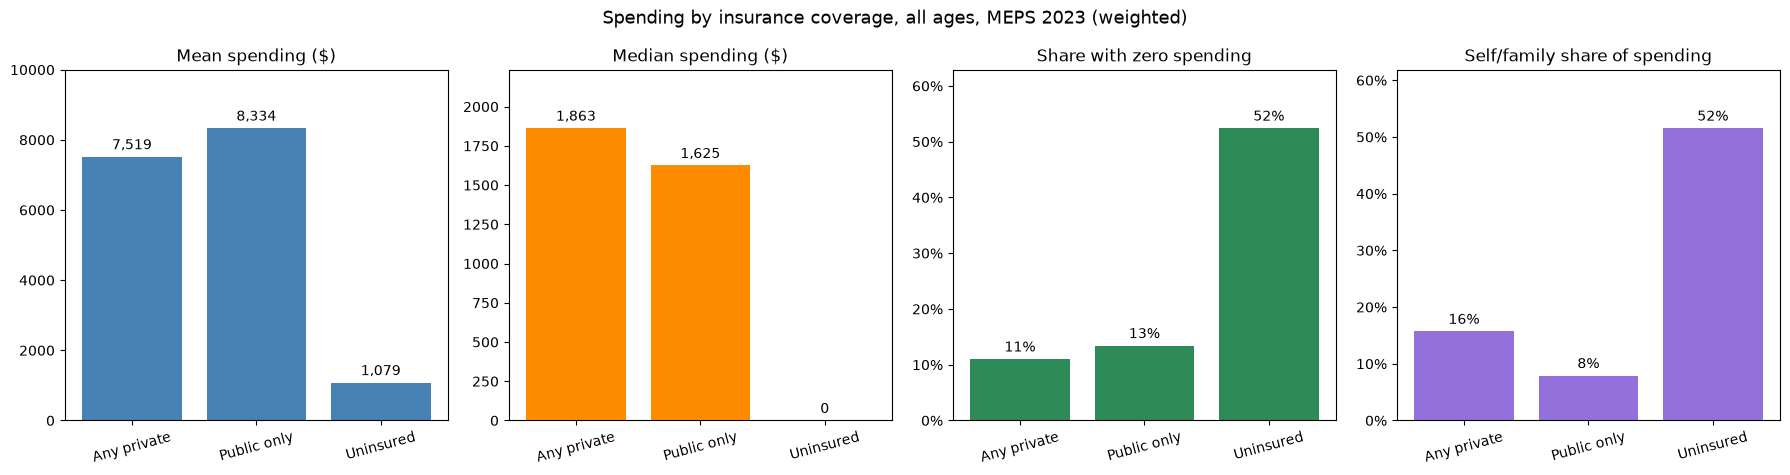

In [404]:
by_cov = ins.groupby("coverage").apply(ins_summary, include_groups=False).loc[["Any private", "Public only", "Uninsured"]]

fig, axes = plt.subplots(1, 4, figsize=(18, 4.8))
specs = [
    ("mean", "Mean spending ($)", "steelblue", "{:,.0f}"),
    ("median", "Median spending ($)", "darkorange", "{:,.0f}"),
    ("zero_share", "Share with zero spending", "seagreen", "{:.0%}"),
    ("self_pay_share", "Self/family share of spending", "mediumpurple", "{:.0%}"),
]
for ax, (col, title, color, fmt) in zip(axes, specs):
    bars = ax.bar(by_cov.index, by_cov[col], color=color)
    ax.bar_label(bars, labels=[fmt.format(v) for v in by_cov[col]], padding=3)
    ax.set_title(title)
    ax.set_ylim(0, by_cov[col].max() * 1.2)
    ax.tick_params(axis="x", labelrotation=15)
    if col in ("zero_share", "self_pay_share"):
        ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
fig.suptitle("Spending by insurance coverage, all ages, MEPS 2023 (weighted)", fontsize=13)
fig.tight_layout()
plt.show()

The uninsured stand out. About half of them spent nothing in 2023, and their median is zero. About half of what they did spend was paid out of pocket. Among people who are insured, public-only and private coverage have similar overall medians.

### Coverage mix by age

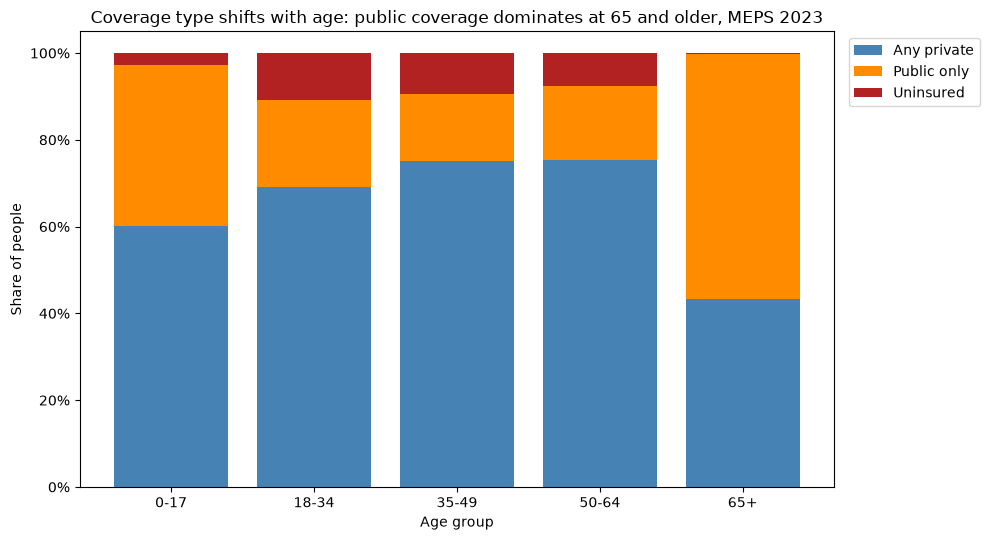

In [405]:
mix = pd.crosstab(ins["agegrp"], ins["coverage"], values=ins["PERWT23F"], aggfunc="sum", normalize="index")
mix = mix[["Any private", "Public only", "Uninsured"]]

fig, ax = plt.subplots(figsize=(10, 5.5))
bottom = np.zeros(len(mix))
for col, color in zip(mix.columns, ["steelblue", "darkorange", "firebrick"]):
    ax.bar(mix.index.astype(str), mix[col], bottom=bottom, label=col, color=color)
    bottom += mix[col].values
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set_xlabel("Age group")
ax.set_ylabel("Share of people")
ax.set_title("Coverage type shifts with age: public coverage dominates at 65 and older, MEPS 2023")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
fig.tight_layout()
plt.show()

Coverage changes sharply with age. Public-only coverage becomes the most common type at 65 and older (about 56%), and private coverage peaks at about 75% between 35 and 64. Uninsurance is about 10% among adults 18 to 49 and nearly absent at 65 and older. Because coverage tracks age this closely, the raw comparisons above mix age with insurance, so the next chart adjusts for it.

### Within age groups: median spending by coverage

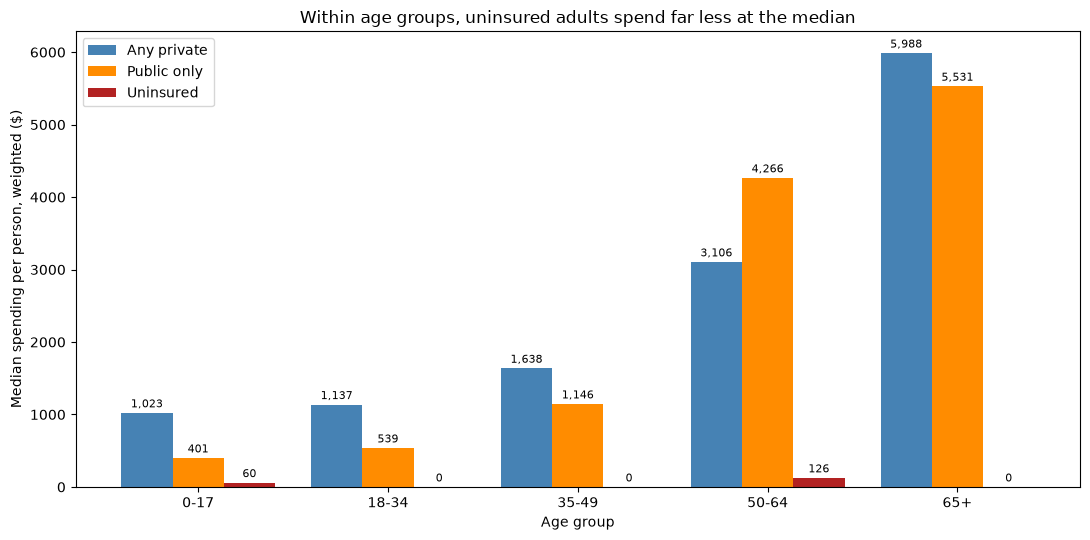

In [406]:
within = ins.groupby(["agegrp", "coverage"], observed=True).apply(
    lambda g: ins_summary(g)["median"], include_groups=False
).unstack()[["Any private", "Public only", "Uninsured"]]

x = np.arange(len(within.index))
width = 0.27
fig, ax = plt.subplots(figsize=(11, 5.5))
for i, (col, color) in enumerate(zip(within.columns, ["steelblue", "darkorange", "firebrick"])):
    bars = ax.bar(x + (i - 1) * width, within[col], width, label=col, color=color)
    ax.bar_label(bars, labels=[f"{v:,.0f}" for v in within[col]], padding=2, fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels(within.index.astype(str))
ax.set_xlabel("Age group")
ax.set_ylabel("Median spending per person, weighted ($)")
ax.set_title("Within age groups, uninsured adults spend far less at the median")
ax.legend()
fig.tight_layout()
plt.show()

Within age groups, uninsured people have much lower medians at every age. Among insured people, the pattern changes with age: private coverage has the higher median in the working ages, and public-only coverage has the higher median at 50 to 64. From 65 the two are close.

Median spending can be zero for the uninsured, so these comparisons really reflect whether people use care at all.

### Zero-spending share within age groups

Lower coverage usually means lower use, so the share with zero spending is shown separately.

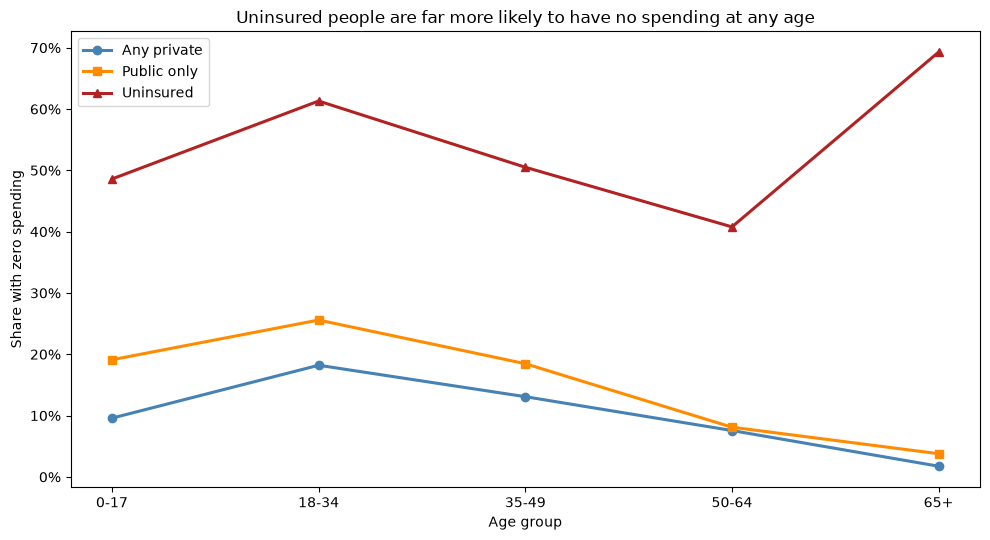

In [407]:
zero = ins.groupby(["agegrp", "coverage"], observed=True).apply(
    lambda g: np.average(g["TOTEXP23"] == 0, weights=g["PERWT23F"]), include_groups=False
).unstack()[["Any private", "Public only", "Uninsured"]]

fig, ax = plt.subplots(figsize=(10, 5.5))
for col, color, marker in zip(zero.columns, ["steelblue", "darkorange", "firebrick"], ["o", "s", "^"]):
    ax.plot(zero.index.astype(str), zero[col], marker=marker, lw=2.2, color=color, label=col)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set_xlabel("Age group")
ax.set_ylabel("Share with zero spending")
ax.set_title("Uninsured people are far more likely to have no spending at any age")
ax.legend()
fig.tight_layout()
plt.show()

The uninsured have the highest zero-spending share in every age group. The gap is largest at 65 and older, but only 14 uninsured people in the sample are that age, so that estimate is unreliable. Among the insured, the zero-spending shares are much closer to each other.

Coverage is not randomly assigned. People who are sicker may be more likely to get public coverage, and healthier people may be more likely to go without. Treat these comparisons as associations, not as the effect of insurance.

## Health status: RTHLTH and MNHLTH

Self-rated health and mental health, from the first interview round (suffix 31). Scale: 1 = excellent, 2 = very good, 3 = good, 4 = fair, 5 = poor. Codes -1 (inapplicable), -7, and -8 are dropped. Children aren't asked these questions, so the section uses adults only.

The last round (suffix 53) is included as a check, since the answers change within a year.

In [408]:
hl = pd.read_stata(
    "../data/raw/meps/2023/h251.dta",
    columns=["TOTEXP23", "AGE23X", "RTHLTH31", "MNHLTH31", "RTHLTH53", "PERWT23F"],
    convert_categoricals=False,
)
hl = hl[hl["AGE23X"] >= 18].copy()
rating_names = {1: "Excellent", 2: "Very good", 3: "Good", 4: "Fair", 5: "Poor"}
hl["agegrp"] = pd.cut(hl["AGE23X"], [17, 34, 49, 64, 130], labels=["18-34", "35-49", "50-64", "65+"])

def hl_median(df):
    s = df.sort_values("TOTEXP23")
    cum = s["PERWT23F"].cumsum() / s["PERWT23F"].sum()
    return s["TOTEXP23"].iloc[np.searchsorted(cum.values, 0.5)]

def hl_summary(g):
    return pd.Series({
        "share": g["PERWT23F"].sum(),
        "mean": np.average(g["TOTEXP23"], weights=g["PERWT23F"]),
        "median": hl_median(g),
        "zero_share": np.average(g["TOTEXP23"] == 0, weights=g["PERWT23F"]),
    })

def valid_rating(df, col):
    return df[df[col].between(1, 5)].assign(rating=lambda x: x[col].map(rating_names))

gen = valid_rating(hl, "RTHLTH31")
men = valid_rating(hl, "MNHLTH31")
print("adults with a valid general-health answer:", len(gen))
print("adults with a valid mental-health answer:", len(men))

adults with a valid general-health answer: 14926
adults with a valid mental-health answer: 14915


### General health: how common, and how much is spent

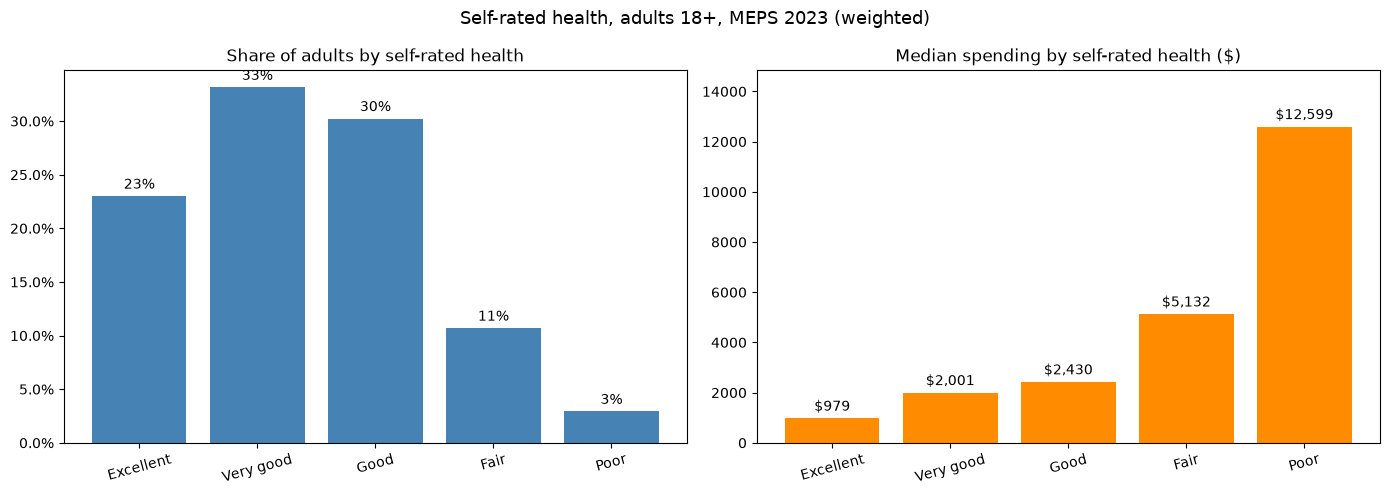

In [409]:
order = list(rating_names.values())
gen_sum = gen.groupby("rating").apply(hl_summary, include_groups=False).loc[order]
gen_sum["share"] = gen_sum["share"] / gen_sum["share"].sum()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
bars = axes[0].bar(gen_sum.index, gen_sum["share"], color="steelblue")
axes[0].bar_label(bars, labels=[f"{v:.0%}" for v in gen_sum["share"]], padding=3)
axes[0].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
axes[0].set_title("Share of adults by self-rated health")

bars = axes[1].bar(gen_sum.index, gen_sum["median"], color="darkorange")
axes[1].bar_label(bars, labels=[f"${v:,.0f}" for v in gen_sum["median"]], padding=3)
axes[1].set_title("Median spending by self-rated health ($)")
axes[1].set_ylim(0, gen_sum["median"].max() * 1.18)

for ax in axes:
    ax.tick_params(axis="x", labelrotation=15)
fig.suptitle("Self-rated health, adults 18+, MEPS 2023 (weighted)", fontsize=13)
fig.tight_layout()
plt.show()

Most adults rate their health as very good or good. Median spending climbs steadily as the rating worsens, from about $980 for excellent to about $12,600 for poor.

### Within age groups: the rating gradient holds at every age

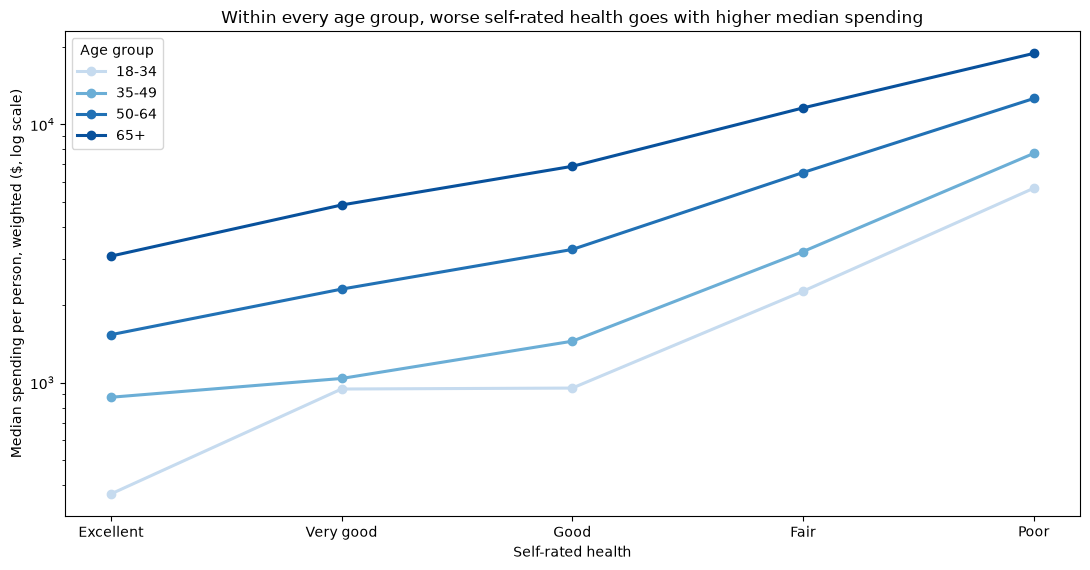

In [410]:
gen_age = gen.groupby(["agegrp", "rating"], observed=True).apply(hl_median, include_groups=False).unstack()[order]

fig, ax = plt.subplots(figsize=(11, 5.8))
colors = ["#c6dbef", "#6baed6", "#2171b5", "#08519c"]
for (age, row), color in zip(gen_age.iterrows(), colors):
    ax.plot(order, row.values, marker="o", lw=2.2, color=color, label=str(age))
ax.set_yscale("log")
ax.set_xlabel("Self-rated health")
ax.set_ylabel("Median spending per person, weighted ($, log scale)")
ax.set_title("Within every age group, worse self-rated health goes with higher median spending")
ax.legend(title="Age group")
fig.tight_layout()
plt.show()

Self-rated health is strongly tied to age: adults who rate their health excellent have a mean age around 44, and those who rate it poor have a mean age around 58. The line chart shows the gradient survives within every age group, on a log scale, so age does not explain it away.

### Mental health compared with general health

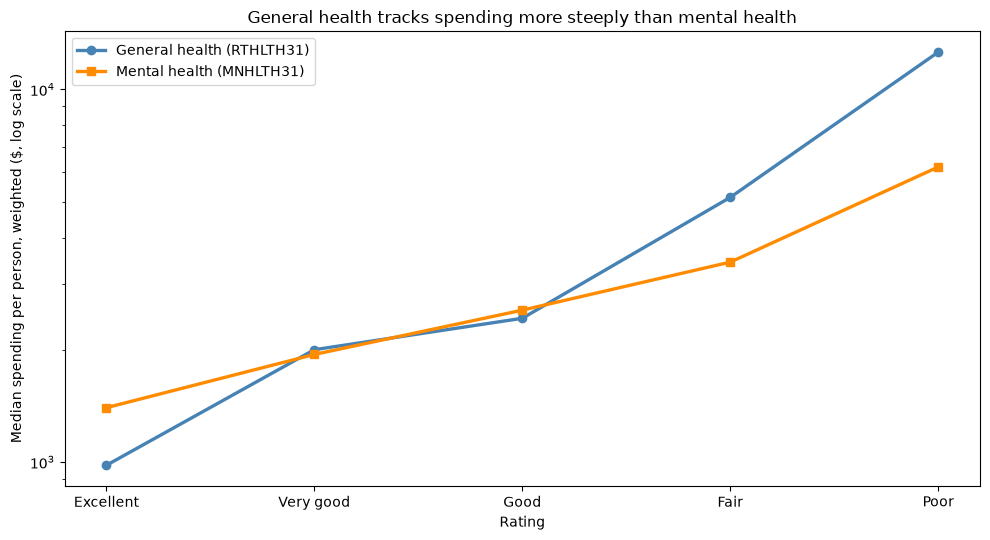

In [411]:
mental_sum = men.groupby("rating").apply(hl_median, include_groups=False).loc[order]
gen_median = gen.groupby("rating").apply(hl_median, include_groups=False).loc[order]

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(order, gen_median.values, marker="o", lw=2.4, color="steelblue", label="General health (RTHLTH31)")
ax.plot(order, mental_sum.values, marker="s", lw=2.4, color="darkorange", label="Mental health (MNHLTH31)")
ax.set_yscale("log")
ax.set_xlabel("Rating")
ax.set_ylabel("Median spending per person, weighted ($, log scale)")
ax.set_title("General health tracks spending more steeply than mental health")
ax.legend()
fig.tight_layout()
plt.show()

Both ratings are linked to spending, but the general-health gradient is steeper. Mental-health medians rise steadily from about $1,400 (excellent) to about $6,200 (poor), against about $980 to $12,600 for general health.

### Do the answers stay the same across the year?

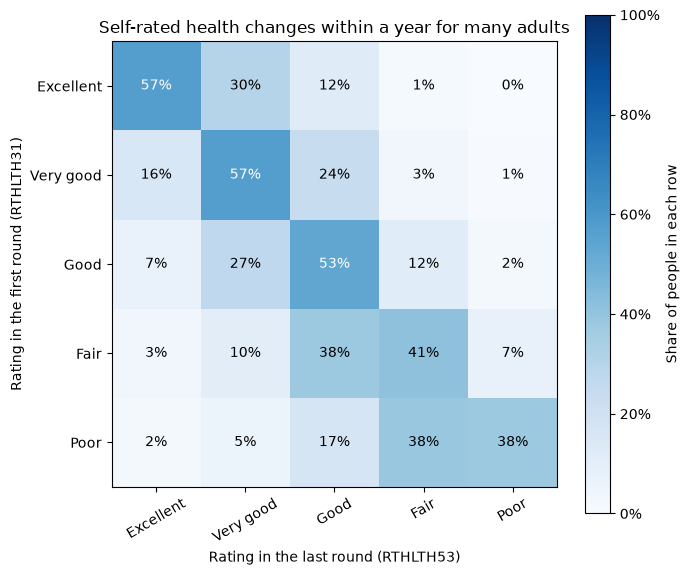

In [412]:
both = hl[hl["RTHLTH31"].between(1, 5) & hl["RTHLTH53"].between(1, 5)].copy()
both["first_round"] = both["RTHLTH31"].map(rating_names)
both["last_round"] = both["RTHLTH53"].map(rating_names)
table = pd.crosstab(both["first_round"], both["last_round"], values=both["PERWT23F"], aggfunc="sum", normalize="index")
table = table.loc[order, order]

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(table.values, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(5)); ax.set_xticklabels(order, rotation=30)
ax.set_yticks(range(5)); ax.set_yticklabels(order)
for i in range(5):
    for j in range(5):
        v = table.values[i, j]
        ax.text(j, i, f"{v:.0%}", ha="center", va="center", color="white" if v > 0.5 else "black")
fig.colorbar(im, ax=ax, label="Share of people in each row", format=plt.matplotlib.ticker.PercentFormatter(1))
ax.set_xlabel("Rating in the last round (RTHLTH53)")
ax.set_ylabel("Rating in the first round (RTHLTH31)")
ax.set_title("Self-rated health changes within a year for many adults")
fig.tight_layout()
plt.show()

Only about 54% of adults give the same rating in the first and last rounds. The diagonal is the agreement; the cells off it show where answers moved. Because the choice of round changes individual answers, state which round you used in the write-up.

## Employment: EMPST31H, EMPST42H, EMPST53H

The "H" versions are imputed, so they have only three categories:
- **1 = employed** at the interview date
- **2 = job to return to** (employed, but on leave)
- **34 = not employed** (codes 3 and 4 combined)

Code -1 (inapplicable) appears mostly among children, so the section uses adults only. The "job to return to" group is very small (about 80 adults), so it's shown but not interpreted.

In [413]:
emp = pd.read_stata(
    "../data/raw/meps/2023/h251.dta",
    columns=["TOTEXP23", "AGE23X", "EMPST31H", "EMPST42H", "EMPST53H", "PERWT23F"],
    convert_categoricals=False,
)
emp = emp[emp["AGE23X"] >= 18].copy()
status_names = {1: "Employed", 2: "Job to return to", 34: "Not employed"}
emp["status"] = emp["EMPST31H"].map(status_names)
emp["agegrp"] = pd.cut(emp["AGE23X"], [17, 34, 49, 64, 130], labels=["18-34", "35-49", "50-64", "65+"])
known = emp[emp["status"].notna()].copy()

def emp_median(df):
    s = df.sort_values("TOTEXP23")
    cum = s["PERWT23F"].cumsum() / s["PERWT23F"].sum()
    return s["TOTEXP23"].iloc[np.searchsorted(cum.values, 0.5)]

def emp_summary(g):
    return pd.Series({
        "share": g["PERWT23F"].sum(),
        "mean": np.average(g["TOTEXP23"], weights=g["PERWT23F"]),
        "median": emp_median(g),
        "zero_share": np.average(g["TOTEXP23"] == 0, weights=g["PERWT23F"]),
        "mean_age": np.average(g["AGE23X"], weights=g["PERWT23F"]),
    })

print("adults with a valid employment answer:", len(known))

adults with a valid employment answer: 14969


### Spending by employment status

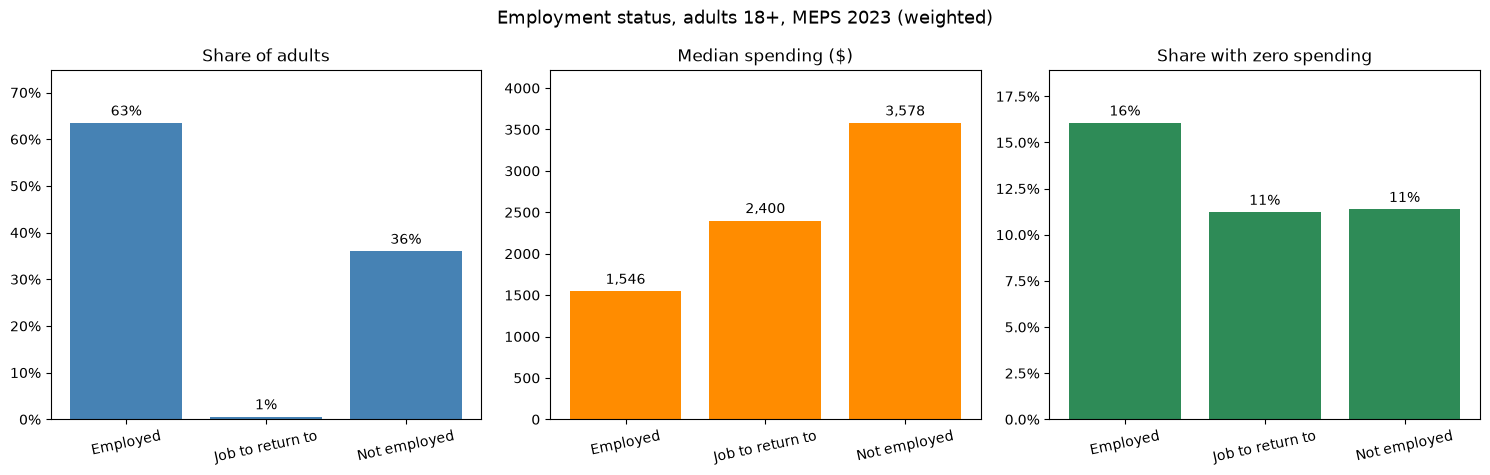

In [414]:
order = ["Employed", "Job to return to", "Not employed"]
by_status = known.groupby("status").apply(emp_summary, include_groups=False).loc[order]
by_status["share"] = by_status["share"] / by_status["share"].sum()

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
specs = [("share", "Share of adults", "steelblue", "{:.0%}"),
         ("median", "Median spending ($)", "darkorange", "{:,.0f}"),
         ("zero_share", "Share with zero spending", "seagreen", "{:.0%}")]
for ax, (col, title, color, fmt) in zip(axes, specs):
    bars = ax.bar(by_status.index, by_status[col], color=color)
    ax.bar_label(bars, labels=[fmt.format(v) for v in by_status[col]], padding=3)
    ax.set_title(title)
    ax.set_ylim(0, by_status[col].max() * 1.18)
    ax.tick_params(axis="x", labelrotation=12)
    if col in ("share", "zero_share"):
        ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
fig.suptitle("Employment status, adults 18+, MEPS 2023 (weighted)", fontsize=13)
fig.tight_layout()
plt.show()

Not employed adults have a higher median ($3,600) than employed adults ($1,500). They're also much older on average, about 56 against about 44, so this raw gap mostly reflects age and retirement, not employment itself.

### Within age groups: is the gap still there?

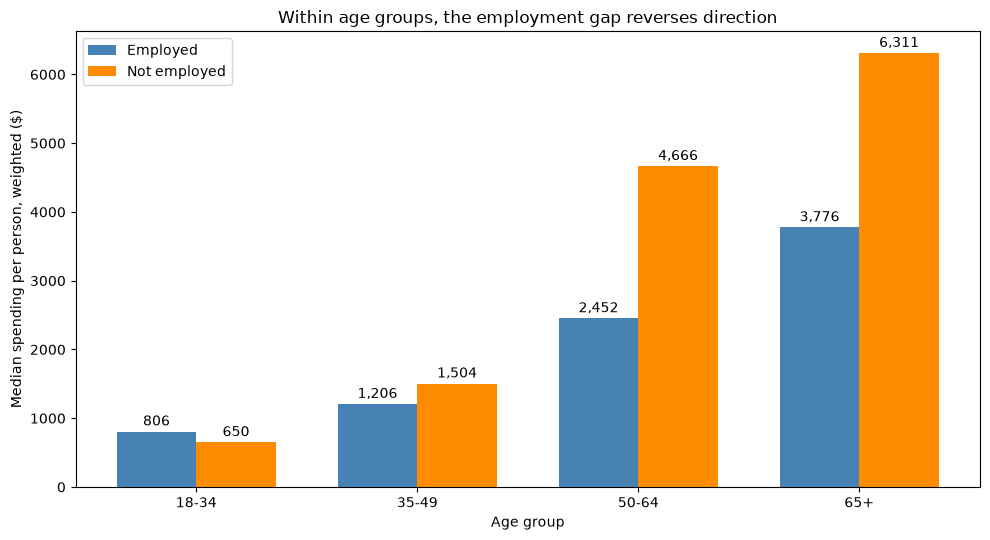

In [415]:
within = known[known["status"].isin(["Employed", "Not employed"])].groupby(
    ["agegrp", "status"], observed=True).apply(emp_median, include_groups=False).unstack()

x = np.arange(len(within.index))
width = 0.36
fig, ax = plt.subplots(figsize=(10, 5.5))
for i, (col, color) in enumerate(zip(["Employed", "Not employed"], ["steelblue", "darkorange"])):
    bars = ax.bar(x + (i - 0.5) * width, within[col], width, label=col, color=color)
    ax.bar_label(bars, labels=[f"{v:,.0f}" for v in within[col]], padding=2)
ax.set_xticks(x)
ax.set_xticklabels(within.index.astype(str))
ax.set_xlabel("Age group")
ax.set_ylabel("Median spending per person, weighted ($)")
ax.set_title("Within age groups, the employment gap reverses direction")
ax.legend()
fig.tight_layout()
plt.show()

Within each age group, the picture changes. At 18 to 34, employed adults have a slightly higher median. From 35 on, not-employed adults spend more, which is the opposite of the raw comparison. At 65 and older, about 75% are not employed, so there are few employed adults to compare against in that group.

### Employment mix by age

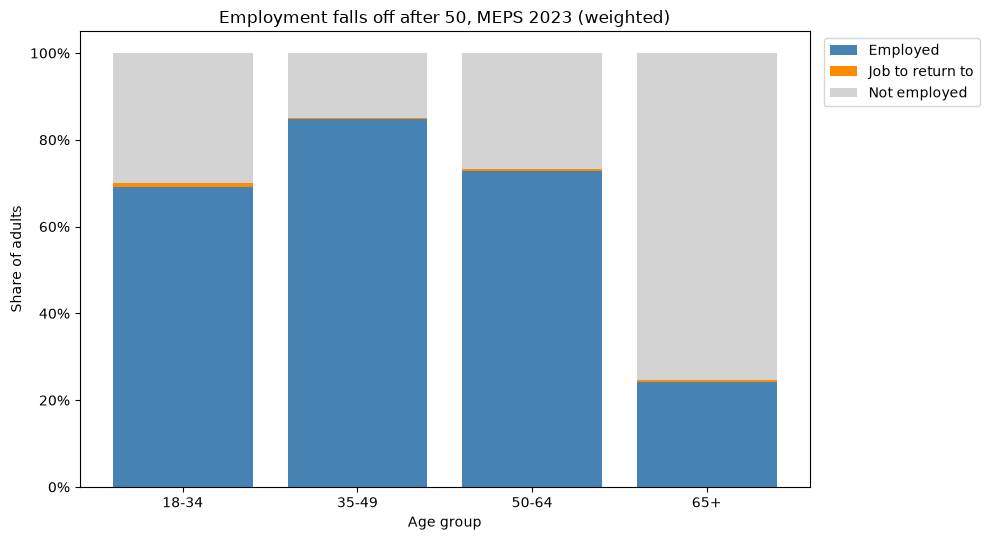

In [416]:
mix = pd.crosstab(known["agegrp"], known["status"], values=known["PERWT23F"], aggfunc="sum", normalize="index")
mix = mix[order]

fig, ax = plt.subplots(figsize=(10, 5.5))
bottom = np.zeros(len(mix))
for col, color in zip(mix.columns, ["steelblue", "darkorange", "lightgrey"]):
    ax.bar(mix.index.astype(str), mix[col], bottom=bottom, label=col, color=color)
    bottom += mix[col].values
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set_xlabel("Age group")
ax.set_ylabel("Share of adults")
ax.set_title("Employment falls off after 50, MEPS 2023 (weighted)")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
fig.tight_layout()
plt.show()

Employment is the norm through the working ages: about 85% of adults 35 to 49 are employed. It falls to about 73% at 50 to 64 and about 24% at 65 and older. Because not-employed status is concentrated at older ages, it mostly stands in for age.

### Is the status stable across the year?

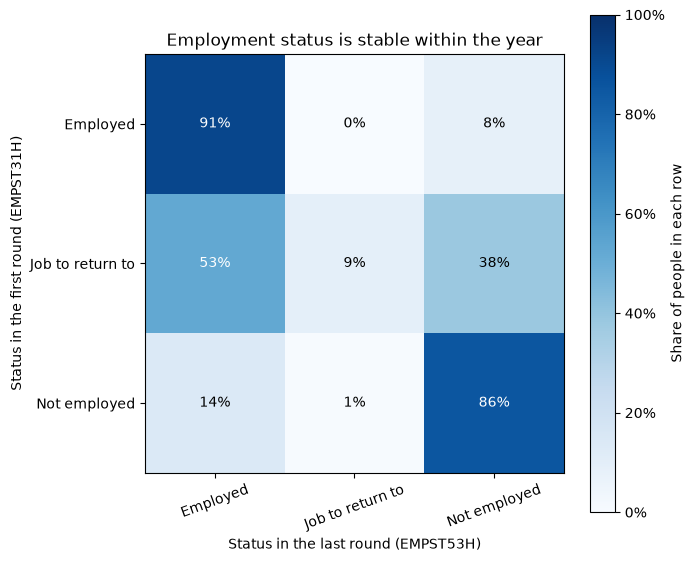

In [417]:
both = emp[emp["EMPST31H"].isin([1, 2, 34]) & emp["EMPST53H"].isin([1, 2, 34])].copy()
both["first"] = both["EMPST31H"].map(status_names)
both["last"] = both["EMPST53H"].map(status_names)
table = pd.crosstab(both["first"], both["last"], values=both["PERWT23F"], aggfunc="sum", normalize="index")
table = table.loc[order, order]

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(table.values, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(3)); ax.set_xticklabels(order, rotation=20)
ax.set_yticks(range(3)); ax.set_yticklabels(order)
for i in range(3):
    for j in range(3):
        v = table.values[i, j]
        ax.text(j, i, f"{v:.0%}", ha="center", va="center", color="white" if v > 0.5 else "black")
fig.colorbar(im, ax=ax, label="Share of people in each row", format=plt.matplotlib.ticker.PercentFormatter(1))
ax.set_xlabel("Status in the last round (EMPST53H)")
ax.set_ylabel("Status in the first round (EMPST31H)")
ax.set_title("Employment status is stable within the year")
fig.tight_layout()
plt.show()

Employment is much more stable across the year than self-rated health was. About 89% of adults have the same status in the first and last rounds. Most of the movement is between employed and not employed, and it's small.

## Patterns across variables

These charts combine factors that were explored one at a time above. Everything uses adults 18+, weighted by `PERWT23F`.

Three questions:
1. Who makes up the top 5% of spenders?
2. For each factor, does it change *whether* people spend, or *how much* they spend among those who do?
3. Do age and chronic conditions combine in a way that adds up?

In [418]:
pat_cols = ["TOTEXP23", "AGE23X", "SEX", "RTHLTH31", "INSCOV23", "OFTSMK53", "PERWT23F",
            "HIBPDX", "CHDDX", "MIDX", "STRKDX", "EMPHDX", "CHOLDX", "CANCERDX", "ARTHDX"]
pat = pd.read_stata("../data/raw/meps/2023/h251.dta", columns=pat_cols, convert_categoricals=False)
pat = pat[pat["AGE23X"] >= 18].copy()

dx_flags = ["HIBPDX", "CHDDX", "MIDX", "STRKDX", "EMPHDX", "CHOLDX", "CANCERDX", "ARTHDX"]
pat["n_conditions"] = pat[dx_flags].eq(1).sum(axis=1)
pat["chronic"] = (pat["n_conditions"] > 0).astype(int)
pat["age65"] = (pat["AGE23X"] >= 65).astype(int)
pat["poor_health"] = pat["RTHLTH31"].isin([4, 5]).astype(int)
pat["uninsured"] = (pat["INSCOV23"] == 3).astype(int)
pat["smoker"] = pat["OFTSMK53"].isin([1, 2]).astype(int)
pat["agegrp"] = pd.cut(pat["AGE23X"], [17, 34, 49, 64, 130], labels=["18-34", "35-49", "50-64", "65+"])

def weighted_median(df, col):
    s = df.sort_values(col)
    cum = s["PERWT23F"].cumsum() / s["PERWT23F"].sum()
    return s[col].iloc[np.searchsorted(cum.values, 0.5)]

ranked = pat.sort_values("TOTEXP23", ascending=False)
share_so_far = ranked["PERWT23F"].cumsum() / ranked["PERWT23F"].sum()
pat["top5"] = 0
pat.loc[ranked.index[share_so_far <= 0.05], "top5"] = 1
print("weighted top-5% threshold ($):", ranked.loc[ranked.index[share_so_far <= 0.05], "TOTEXP23"].min())

weighted top-5% threshold ($): 38395


### Who makes up the top 5% of spenders?

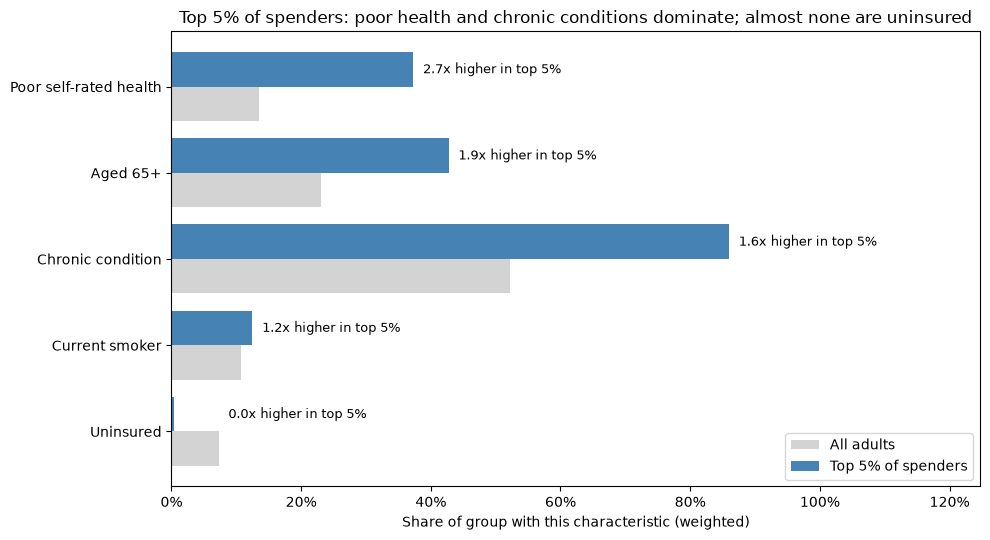

In [419]:
flags = {"Aged 65+": "age65", "Chronic condition": "chronic", "Poor self-rated health": "poor_health",
         "Current smoker": "smoker", "Uninsured": "uninsured"}

top, everyone = pat[pat["top5"] == 1], pat
rows = []
for label, col in flags.items():
    in_top = np.average(top[col], weights=top["PERWT23F"])
    overall = np.average(everyone[col], weights=everyone["PERWT23F"])
    rows.append({"factor": label, "top5": in_top, "overall": overall, "lift": in_top / overall})
profile = pd.DataFrame(rows).set_index("factor").sort_values("lift")

fig, ax = plt.subplots(figsize=(10, 5.5))
y = np.arange(len(profile))
ax.barh(y - 0.2, profile["overall"], 0.4, color="lightgrey", label="All adults")
ax.barh(y + 0.2, profile["top5"], 0.4, color="steelblue", label="Top 5% of spenders")
ax.set_yticks(y)
ax.set_yticklabels(profile.index)
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
for yi, (_, row) in zip(y, profile.iterrows()):
    ax.text(max(row["top5"], row["overall"]) + 0.015, yi + 0.2, f"{row['lift']:.1f}x higher in top 5%",
            va="center", fontsize=9)
ax.set_xlim(0, profile["top5"].max() * 1.45)
ax.set_xlabel("Share of group with this characteristic (weighted)")
ax.set_title("Top 5% of spenders: poor health and chronic conditions dominate; almost none are uninsured")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

Among the top 5% of spenders, 86% have a chronic condition (in the rest of the adult population it's about half) and 37% report poor health. They're also older, with 43% aged 65 and over. Almost none are uninsured.

These are the people a cost model has to get right, since they make up most of the spending.

### Does a factor change whether people spend, how much they spend, or both?

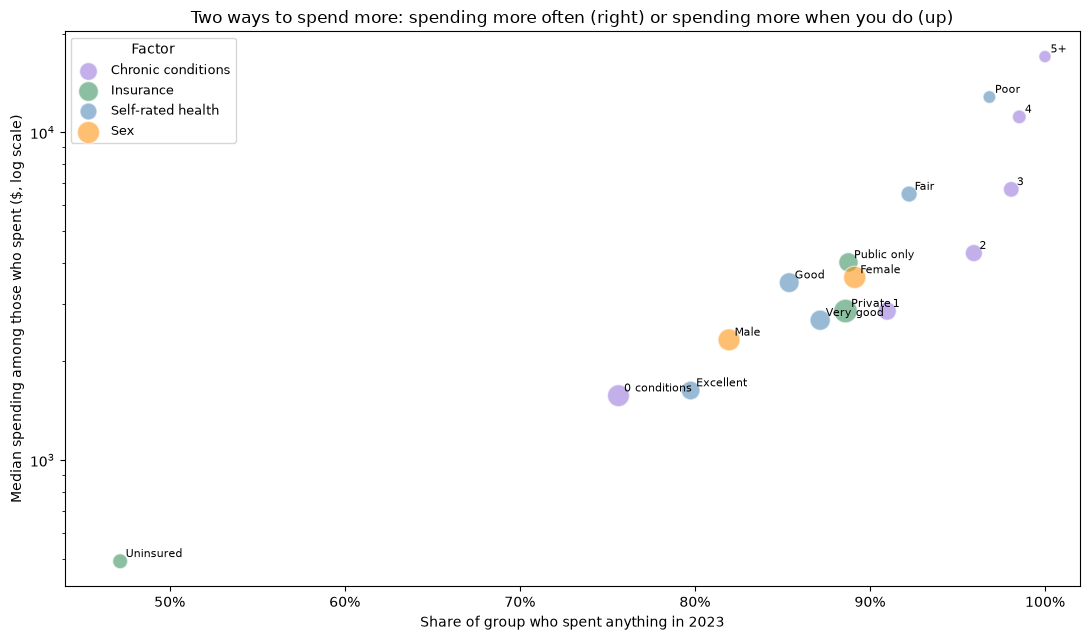

In [420]:
spenders = pat[pat["TOTEXP23"] > 0]

def level_point(df, col, label, names=None):
    out = []
    for k, g in df.groupby(col):
        if k < 0 or g["PERWT23F"].sum() < 1e5:
            continue
        spend_share = np.average(g["TOTEXP23"] > 0, weights=g["PERWT23F"])
        pos = g[g["TOTEXP23"] > 0]
        out.append({
            "factor": label,
            "level": names.get(k, str(k)) if names else str(k),
            "any_spend": spend_share,
            "median_if_spend": weighted_median(pos, "TOTEXP23"),
            "people": g["PERWT23F"].sum(),
        })
    return out

points = []
points += level_point(pat, "SEX", "Sex", {1: "Male", 2: "Female"})
points += level_point(pat, "INSCOV23", "Insurance", {1: "Private", 2: "Public only", 3: "Uninsured"})
points += level_point(pat, "RTHLTH31", "Self-rated health", {1: "Excellent", 2: "Very good", 3: "Good", 4: "Fair", 5: "Poor"})
pat["cond5"] = pat["n_conditions"].clip(upper=5)
points += level_point(pat, "cond5", "Chronic conditions", {0: "0 conditions", 1: "1", 2: "2", 3: "3", 4: "4", 5: "5+"})
points = pd.DataFrame(points)

fig, ax = plt.subplots(figsize=(11, 6.5))
palette = {"Sex": "darkorange", "Insurance": "seagreen", "Self-rated health": "steelblue", "Chronic conditions": "mediumpurple"}
for factor, g in points.groupby("factor"):
    ax.scatter(g["any_spend"], g["median_if_spend"], s=30 + 260 * np.sqrt(g["people"] / points["people"].max()), alpha=0.55,
               color=palette[factor], label=factor, edgecolor="white")
    for _, r in g.iterrows():
        ax.annotate(r["level"], (r["any_spend"], r["median_if_spend"]), xytext=(4, 3),
                    textcoords="offset points", fontsize=8)
ax.set_yscale("log")
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set_xlabel("Share of group who spent anything in 2023")
ax.set_ylabel("Median spending among those who spent ($, log scale)")
ax.set_title("Two ways to spend more: spending more often (right) or spending more when you do (up)")
ax.legend(title="Factor", loc="upper left", fontsize=9)
ax.set_xlim(0.44, 1.02)
fig.tight_layout()
plt.show()

Each point is one group, and the bubble size reflects how many people it contains. Health and chronic conditions push both ways: people in poor health are more likely to spend *and* spend more when they do.

Insurance is different. The uninsured are far less likely to spend at all, and those who do spend are at the low end too. Sex shows women spending more often, and considerably more when they spend (a median of about $3,600 against $2,300).

### Age and chronic conditions together

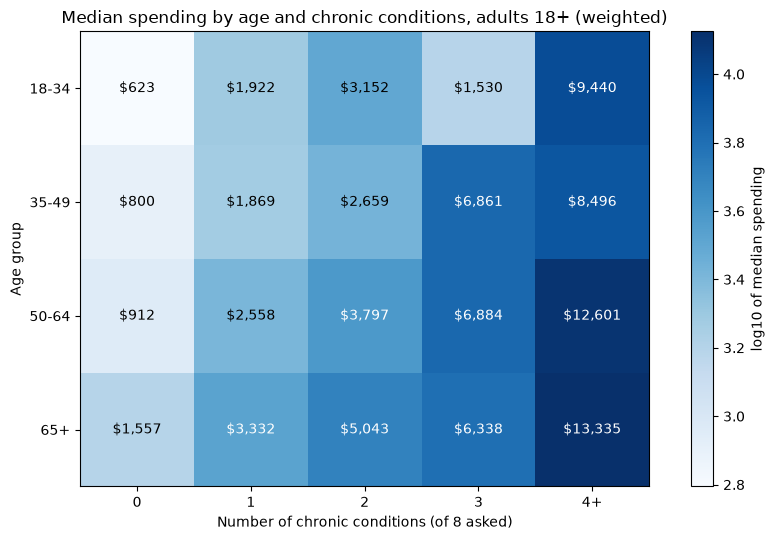

In [421]:
heat_cats = ["0", "1", "2", "3", "4+"]
pat["cond_cat"] = pat["n_conditions"].clip(upper=4).map({0: "0", 1: "1", 2: "2", 3: "3", 4: "4+"})
grid = pat.groupby(["agegrp", "cond_cat"], observed=True).apply(
    lambda g: weighted_median(g, "TOTEXP23") if g["PERWT23F"].sum() > 0 else np.nan,
    include_groups=False,
).unstack()[heat_cats]

fig, ax = plt.subplots(figsize=(9, 5.5))
im = ax.imshow(np.log10(grid.values), cmap="Blues")
ax.set_xticks(range(len(heat_cats))); ax.set_xticklabels(heat_cats)
ax.set_yticks(range(len(grid.index))); ax.set_yticklabels(grid.index.astype(str))
for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        v = grid.values[i, j]
        ax.text(j, i, f"${v:,.0f}", ha="center", va="center",
                color="white" if np.log10(v) > np.nanmean(np.log10(grid.values)) else "black")
cbar = fig.colorbar(im, ax=ax)
cbar.set_label("log10 of median spending")
ax.set_xlabel("Number of chronic conditions (of 8 asked)")
ax.set_ylabel("Age group")
ax.set_title("Median spending by age and chronic conditions, adults 18+ (weighted)")
fig.tight_layout()
plt.show()

Both age and conditions raise median spending, and the effects combine. Adults under 35 with four or more conditions have a median in the thousands, and the same count at 65 and older is well into five figures. Reading across a row shows the condition effect at a fixed age, and reading down a column shows the age effect at a fixed condition count.

# Conclusions and readiness for modeling

This section summarizes what the exploration showed, the decisions the models depend on, and what's still open. Nothing here is a model result yet.

## 1. Target

**Outcome:** `TOTEXP23`, total health care expenditure in 2023, all payers.

- About 14% of people spend nothing in a year, so the outcome has a point mass at zero plus a right-skewed positive part.
- Among spenders, the log of spending is close to symmetric, which suits a log-link model.
- The top 1% of people account for about 20% of weighted spending, and the top 10% for about 65%. Evaluation should therefore look at the tail, not only at averages.

**Open choice:** if the project is framed as an insurer's claim cost, the alternative target is `TOTPRV23` (private-insurance payments), limited to people with private coverage. That's a different question, so decide it before modeling.

## 2. Candidate predictors

These were all checked in the cell below: each exists in both 2023 and 2024 under the year-suffixed name.

| Group | Variables | Notes |
|---|---|---|
| Demographics | `AGE23X`, `SEX`, `REGION23`, `MARRY23X` | Marital status is for adults only |
| Income and coverage | `POVLEV23`, `INSCOV23` | `POVLEV23` alone: `FAMINC23` and `POVCAT23` carry almost the same information |
| Education | `EDUCYR`, `HIDEG` | `EDUCYR` is recorded at first entry to MEPS, so check the codebook before use |
| Self-rated health | `RTHLTH31`, `MNHLTH31` | Round 31 chosen for the models. Only about 54% of adults give the same rating in round 53 |
| Diagnoses | `HIBPDX`, `CHDDX`, `MIDX`, `STRKDX`, `EMPHDX`, `CHOLDX`, `CANCERDX`, `ARTHDX` | Adults only. `ASTHDX` and `DIABDX_M18` were also asked of children |
| Lifestyle | `OFTSMK53` | Adults only |
| Employment | `EMPST31H` | Round 31, imputed version. Closely tied to age |

In [422]:
candidates = ["AGE23X", "SEX", "REGION23", "MARRY23X", "POVLEV23", "INSCOV23", "EDUCYR", "HIDEG",
              "RTHLTH31", "MNHLTH31", "HIBPDX", "CHDDX", "MIDX", "STRKDX", "EMPHDX", "CHOLDX",
              "CANCERDX", "ARTHDX", "ASTHDX", "DIABDX_M18", "OFTSMK53", "EMPST31H"]

with pd.io.stata.StataReader("../data/raw/meps/2023/h251.dta") as r:
    names_2023 = set(r.variable_labels())
with pd.io.stata.StataReader("../data/raw/meps/2024/h256.dta") as r:
    names_2024 = set(r.variable_labels())

rows = []
for c in candidates:
    c24 = c.replace("23", "24") if "23" in c else c
    rows.append({"variable": c, "in_2023": c in names_2023, "in_2024_as": c24, "in_2024": c24 in names_2024})
check = pd.DataFrame(rows)
print(check.to_string(index=False))
print("\nall present in both years:", bool(check[["in_2023", "in_2024"]].all().all()))

  variable  in_2023 in_2024_as  in_2024
    AGE23X     True     AGE24X     True
       SEX     True        SEX     True
  REGION23     True   REGION24     True
  MARRY23X     True   MARRY24X     True
  POVLEV23     True   POVLEV24     True
  INSCOV23     True   INSCOV24     True
    EDUCYR     True     EDUCYR     True
     HIDEG     True      HIDEG     True
  RTHLTH31     True   RTHLTH31     True
  MNHLTH31     True   MNHLTH31     True
    HIBPDX     True     HIBPDX     True
     CHDDX     True      CHDDX     True
      MIDX     True       MIDX     True
    STRKDX     True     STRKDX     True
    EMPHDX     True     EMPHDX     True
    CHOLDX     True     CHOLDX     True
  CANCERDX     True   CANCERDX     True
    ARTHDX     True     ARTHDX     True
    ASTHDX     True     ASTHDX     True
DIABDX_M18     True DIABDX_M18     True
  OFTSMK53     True   OFTSMK53     True
  EMPST31H     True   EMPST31H     True

all present in both years: True


## 3. Variables to keep out of the models

- **All payer and expenditure columns** (`TOT*`, including `TOTTCH23`), along with utilization counts such as visits and prescriptions. Each is partly the outcome, so the model would be learning from its own answer.
- **Survey design columns** (`VARSTR`, `VARPSU`). They're used for standard errors, not as features.
- **Person ID** (`DUPERSID`). It identifies a person, but it's not a predictor.
- **`PERWT23F`** is a sample weight. It's used in the fit and in every average, never as a feature.
- **Race and ethnicity** (`RACETHX`) was not analyzed here. Whether to use it, and how, is a decision to make on purpose before modeling.

## 4. Cleaning rules

These follow from what the codebook and the value counts showed:

| Code | Meaning | Rule |
|---|---|---|
| `-1` | Inapplicable (usually children, or questions not asked) | Keep as its own category, not missing. Usually an age split handles it |
| `-7`, `-8` | Refused, don't know | Treat as missing |
| `-15` | Cancer questions only | Treat as missing |
| `-230` (`FAMINC23`), `-1.57` (`POVLEV23`) | Real negative values | Keep as-is |
| `8` in `HIDEG` | Under 16 | Inapplicable. Drop from adult analyses |

**Who's in the sample:** 148 people have no age or region. Either drop them or keep them with a flag, and say which in the write-up.

**Population:** adults (18+) are the cleanest group for the diagnosis, lifestyle, and marital questions. Children have different questions. A separate model for children, or a model on adults only, is a choice to make explicitly.

## 5. What the exploration showed

- **Age is the dominant factor.** Mean spending rises from about $2,800 at ages 0 to 17 to about $15,000 at 65 and older. Most other factors partly reflect age.
- **Chronic conditions and self-rated health have large effects that persist within age groups.** Among adults, the median ratio with and without a condition is about 2 to 3 times after adjusting for age. Self-rated health shows a gradient at every age.
- **Health and conditions affect both whether someone spends and how much.** This points toward a two-part structure, or a Tweedie-type model that handles zeros and amounts together.
- **The uninsured are unusual.** About 52% spend nothing, and their median is zero. The insured have much higher spending, and public-only and private coverage look similar overall.
- **Income mostly shifts the probability of spending, not the amount.** Among spenders, income has essentially no rank correlation with spending. The zero-spending share falls steadily with income.
- **Women spend more than men, mostly at ages 18 to 64.** This is a raw gap, and the cause hasn't been tested.
- **Smoking is associated with lower medians but similar means.** Smoking also drives several of the diagnoses, so adjusting for them changes what the smoking coefficient means.
- **Employment mostly tracks age.** Its extra contribution once age is in the model is untested, so check it when the models are fit.
- **The top 5% of spenders** are mostly people with chronic conditions and poor self-rated health, and almost none are uninsured. A model has to get this group right, since it accounts for much of the total.

## 6. Data decisions for the models

1. **Weights.** Use `PERWT23F` for every fit and every reported average. The weighted mean overall is about 11% lower than the unweighted mean, so the weights change the answer.
2. **Survey design.** For honest standard errors, cluster by `VARSTR` and `VARPSU`. Point estimates don't need them.
3. **Zero-weight people.** 456 people have a weight of zero. Check the documentation for why, then exclude them from the fits.
4. **Train and test years.** Train on 2023, test on 2024, as planned.
5. **Overlap between years.** About 47% of 2023 people also appear in 2024. Test on all 2024 people and on the 2024 people who weren't in 2023, and report both. The gap between the two shows how much the overlap flatters the model.
6. **Concurrent or prospective.** Health, conditions, and employment are measured in the same year as spending, so the model describes a same-year relationship. A forecast from prior-year information would need different predictors. Decide before writing up results.

## 7. Open decisions before modeling

- **Target:** total spending (`TOTEXP23`), or private-insurance payments (`TOTPRV23`) among the privately insured?
- **Population:** all ages, or adults only?
- **Concurrent or prospective** (see point 6 above).
- **Race and ethnicity:** include, exclude, or use only for fairness checks?
- **Education:** confirm the meaning of `EDUCYR` in the codebook before using it.
- **Round:** health and employment change within a year for many people. Use round 31 throughout, and state it.

## 8. Model plan (for the next step)

- **Two-part GLM:** a logistic model for any spending, and a Gamma GLM with a log link for the amount among spenders. Expected spending is the product.
- **Tweedie GLM:** one model for total spending, with a log link. This is the single-model comparison.
- **Gradient boosting** (XGBoost or LightGBM) with a Tweedie or Gamma objective, using the same features and weights.
- **Evaluation:** weighted MAE and deviance on the 2024 test sets, actual-to-expected ratios overall and by segment, and a check of performance in the top 5% of spenders.

Nothing has been modeled yet. This section is the list of decisions to make before writing the first model.